*Text under CC-BY 4.0, code under BSD-3-Clause. (c) 2026 Francesco Mario Antonio Mitrotta.*

# How Smooth Is the Ultimate Load?

[NB10](10_pce_surrogate_open_hole_tension.ipynb) fitted polynomial chaos surrogates to the 12,297 accepted Abaqus runs of the open-hole tension (OHT) plate of [NB9](09_training_campaign_open_hole_tension.ipynb). The first-ply failure load came out almost exact. The peak load, $P_{ULT}$, did not: its error stopped falling at about 0.11, whatever the order (1 to 3) and however many runs, and the surrogate's standard deviation came out 6% low. [Thapa et al. (2021)](https://doi.org/10.1007/s00158-020-02690-5) fitted the same plate's peak load easily, but their load&ndash;displacement curves round over and decline gradually, while ours collapse almost vertically. NB10 ended on a question: is the peak load of our model a **non-smooth** function of the 15 inputs, and is that why the polynomial cannot follow it?

This notebook answers it, and the answer is mostly not about the plate. Along a line on which only $E_1$ changes, the peak load of NB9's model jumps every few runs. Solved again with increments ten times smaller, the same line is smooth except for one jump, where the plate switches between two ways of breaking. The steps: what smoothness means for a polynomial surrogate and how to measure it; what NB10's surrogate leaves unexplained; the line scan with NB9's increments, what its damage maps show and why the increments can change them; the same line with smaller increments; and what physically decides which way the plate breaks.

## Learning goal

By the end of this notebook you will be able to:

- explain why a polynomial expansion converges slowly on an output with jumps, and measure the roughness of a simulation
  output along a line from the differences of its values;
- show that what NB10's surrogate leaves unexplained is a rough layer in the timing of the collapse;
- explain, from the loss of uniqueness once softening starts, why the solver's increments can change where the plate
  breaks, and tell the solver's jumps from the model's by solving the same line with smaller increments;
- read the two collapse paths (late and straight along the net section, early and inclined) off the damage maps, and trace
  which one the plate takes back to the element, the ply and the failure criteria that decide it.

## Prerequisites

[NB8](08_polynomial_chaos_expansion.ipynb) (the Hermite expansion, the point-collocation fit and the relative error $\varepsilon$), [NB9](09_training_campaign_open_hole_tension.ipynb) and [NB10](10_pce_surrogate_open_hole_tension.ipynb) (the campaign, its screening and the surrogate), [NB6](06_open_hole_tension.ipynb) (the plate, its build script, the increment cap `maxinc` and the viscous regularisation $\eta$) and [NB1](01_fiber_tension_single_element.ipynb) (the Hashin criteria $F_{ft}$ and $F_{mt}$, used in Part 5). Nothing beyond them.

First, the imports. Besides NumPy and Matplotlib, the standard library reads the design files and results and
launches the Abaqus runs, SciPy's `cKDTree` finds nearest neighbours in the input space (Part 2), and Matplotlib's
`PolyCollection` draws the mesh (Parts 4 and 5). The PCE functions are NB8's, from `scripts/pce.py`; `drop_failed_frame`
and `acceptance_reason` are NB9's campaign driver's, from `scripts/oht_campaign.py`.

In [1]:
# Standard library: design files (CSV), results (JSON), launching Abaqus (subprocess, sys), paths.
import csv
import json
import subprocess
import sys
from pathlib import Path

# NumPy, Matplotlib (and its PolyCollection for the mesh maps), SciPy's nearest-neighbour search.
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import PolyCollection
from scipy.spatial import cKDTree

# NB8's PCE functions, and NB9's reading and screening of a run.
sys.path.insert(0, "../scripts")
from pce import design_matrix, fit_pce, relative_mse, total_order_indices
from oht_campaign import acceptance_reason, drop_failed_frame

## Part 1 &ndash; What "smooth" means for a polynomial surrogate

### Step 1 &ndash; Convergence depends on smoothness

NB10 ended on a floor: the error of $P_{ULT}$ stopped falling, whatever the order and however many runs. Yet a polynomial
chaos expansion is known to converge. The **Cameron&ndash;Martin theorem**, recalled by
[Xiu & Karniadakis (2002, p. 619)](https://doi.org/10.1137/S1064827501387826), says that for **any** output $y$ with a finite
variance the mean over the inputs of $(y-y_p)^2$ goes to zero as the order $p\to\infty$, where $y_p$ is the expansion
truncated at order $p$ with exact coefficients. Both are true, because the theorem says nothing about **how fast**.

**Smoothness decides how fast.** For an output with $s$ well-behaved derivatives the error of an expansion with $N$ terms
falls like $N^{-s}$, very fast for a smooth output; for an output with a jump the convergence is slow, like $N^{-1}$ for
the mean in the case Chantrasmi et al. treat (one jump), because a polynomial, smooth everywhere, overshoots and rings on
both sides of the jump (the Gibbs phenomenon;
[Chantrasmi et al., 2009, p. 7161](https://doi.org/10.1016/j.jcp.2009.06.024)).

**The budget fixes the order.** With $d=15$ inputs a total-order expansion has $N=\binom{p+d}{d}$ terms, 816 at $p=3$ (NB8,
NB10), and the runs must grow with them: at NB9's oversampling ratio $n_p=15$, order 4 (3,876 terms) would need 58,140 runs.
So the order is set by what you can afford. If the output has jumps, the error at that order stays high, and what is left is a floor.

To see it, take a one-input toy. Its smooth part is NB8's $y_s=e^{\lambda\xi}$, with $\lambda=0.5$. Its rough version
adds a square wave, a layer of small jumps that switches between $+c$ and $-c$ every $w$ in $\xi$:

$$y_r(\xi)=e^{\lambda\xi}+c\,\mathrm{sign}\!\big(\sin(\pi\xi/w)\big),$$

where
- $\xi$ is a standard normal input [-],
- $c=0.22$ is the amplitude of the square wave, so each jump is $2c$ high; $c$ is chosen so that the layer carries
  about 12% of the variance of $y_r$, as the rough part of $P_{ULT}$ does in NB10 [-],
- $w=0.17$ is the distance between two jumps in $\xi$ [-].

Before any fitting, look at them. The next cell defines both functions and plots them over
$\xi\in[-3,3]$, which holds 99.7% of the probability of a standard normal input.

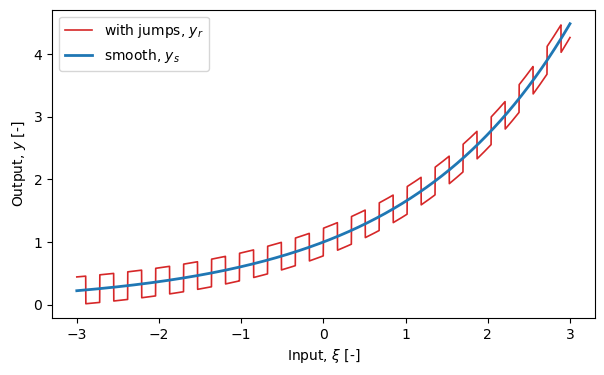

In [2]:
# The toy: NB8's smooth exponential, and the same with a square wave of amplitude c that switches every w in xi.
# lambda = 0.5 [-], c = 0.22 [-] (about 12% of the variance), w = 0.17 [-].
LAM, C_JUMP, W_JUMP = 0.5, 0.22, 0.17


def y_smooth(xi):
    """Smooth toy output y_s = exp(lam xi)."""
    # One exponential per point.
    return np.exp(LAM * xi)


def y_rough(xi):
    """Rough toy output y_r = exp(lam xi) + c sign(sin(pi xi / w)): the smooth one plus a layer of jumps."""
    # The square wave switches sign every W_JUMP.
    return y_smooth(xi) + C_JUMP * np.sign(np.sin(np.pi * xi / W_JUMP))


# Both outputs on a fine grid over [-3, 3]; the rough one is drawn first so the smooth one stays visible on top.
xi_plot = np.linspace(-3.0, 3.0, 3001)
# A figure with one axes.
fig, ax = plt.subplots(figsize=(7.0, 4.0))
ax.plot(xi_plot, y_rough(xi_plot), color="C3", lw=1.2, label="with jumps, $y_r$")
ax.plot(xi_plot, y_smooth(xi_plot), color="C0", lw=2.0, label="smooth, $y_s$")
# Axis labels with symbol and units, then the legend.
ax.set(xlabel=r"Input, $\xi$ [-]", ylabel=r"Output, $y$ [-]")
ax.legend()
plt.show()

The rough toy has the shape of the smooth one, with a **staircase of small steps** on it: the red curve sits $c=0.22$
above the blue one, then $0.22$ below, and back, every $w=0.17$ in $\xi$, about 35 times across the plot. Each step
changes $y_r$ by $2c=0.44$, small against the range of the output (0.2 to 4.5), so the red curve is never far from the blue one.
But the steps together carry 12% of the variance. A polynomial is smooth everywhere: it can follow the blue curve, and
not the steps. The fit below measures what that costs.

The cell fits Hermite expansions of orders 1 to 8 to both functions with `fit_pce` (NB8), from 2,000 random points,
and measures $\varepsilon$ on 100,000 others (seed 15 for both).
The toy has one input, so even order 8 has only 9 terms against 2,000 runs: the runs are never the limit here, and the curves
show the limit of the order alone.

share of the variance of y_r carried by the jumps: 0.118


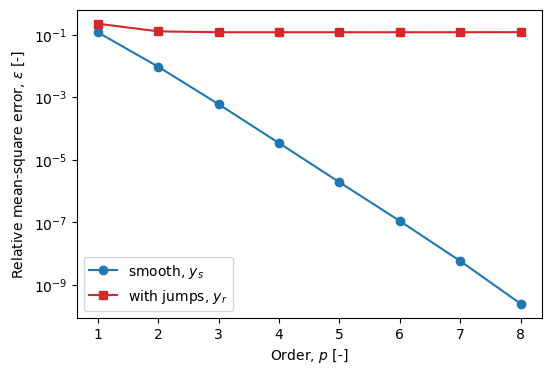

eps at p = 1, 3, 8:  smooth 1.2e-01, 6.0e-04, 2.6e-10;  with jumps 0.221, 0.118, 0.119


In [3]:
# Seed of the training and reference points (shared with the rest of the notebook's toy).
SEED_TOY = 15

# Training and reference points from one stream, and the share of variance the layer of jumps carries.
rng = np.random.default_rng(SEED_TOY)
xi_fit, xi_ref = rng.standard_normal(2000), rng.standard_normal(100_000)
print("share of the variance of y_r carried by the jumps: %.3f" % (C_JUMP ** 2 / y_rough(xi_ref).var()))
# Fit orders 1-8 to both outputs and measure epsilon on the reference points.
orders = np.arange(1, 9)
# One list of epsilon values per toy output.
eps_toy = {f: [] for f in (y_smooth, y_rough)}
for p in orders:
    # The Hermite terms of order up to p for one input.
    alphas = total_order_indices(1, p)
    for f in eps_toy:
        # Fit on the training points, then compare the prediction with f on the reference points.
        a = fit_pce(xi_fit[:, None], f(xi_fit), alphas)
        eps_toy[f].append(relative_mse(f(xi_ref), design_matrix(xi_ref[:, None], alphas) @ a))
# Epsilon against the order, on a log axis.
fig, ax = plt.subplots(figsize=(6.0, 4.0))
ax.semilogy(orders, eps_toy[y_smooth], "o-", color="C0", label="smooth, $y_s$")
ax.semilogy(orders, eps_toy[y_rough], "s-", color="C3", label="with jumps, $y_r$")
ax.set(xlabel="Order, $p$ [-]", ylabel="Relative mean-square error, $\\varepsilon$ [-]")
# Legend, then the numbers behind the curves at p = 1, 3 and 8.
ax.legend()
plt.show()
print("eps at p = 1, 3, 8:  smooth %.1e, %.1e, %.1e;  with jumps %.3f, %.3f, %.3f"
      % (*[eps_toy[y_smooth][k] for k in (0, 2, 7)], *[eps_toy[y_rough][k] for k in (0, 2, 7)]))

The smooth toy behaves as NB8 taught: $\varepsilon$ falls from 0.12 at order 1 to $6\times10^{-4}$ at order 3 and
$2.6\times10^{-10}$ at order 8, a nearly straight line on the log axis. The toy with jumps starts higher and then stops: 0.118
at order 3 and 0.119 at order 8. The error sits at the variance share of the jumps, 0.118: no polynomial of these orders can follow
the jumps. This does not contradict the theorem. An order high enough to resolve steps of width $w$ would follow them,
but that order is far beyond the eight here, and beyond anything a plate with 15 inputs can pay for, so in practice
the error stays on a floor. This is what the plate showed in NB10: an error of about 0.11 for $P_{ULT}$ at order 3,
not falling with more runs. The toy does not prove that the plate has such a layer; it shows what a layer of that
size would do.

### Step 2 &ndash; Measuring roughness along a line

The error curve says that something is not smooth, but not what, and on the plate every point costs an Abaqus run. A
direct measure is to evaluate the output at equally spaced points along a line and look at its **differences**.
[Moré & Wild (2011)](https://doi.org/10.1137/100786125) use them to measure the noise of deterministic simulations,
after Hamming. Take the second difference with spacing $h$,

$$\Delta_h^2y(t)=y(t+2h)-2\,y(t+h)+y(t),$$

where $t$ is the position along the line and $h$ the spacing [-]. For a smooth $y$ it is about $y''h^2$, so it shrinks
fast as $h$ shrinks. For an independent noise of standard deviation $\sigma$ it does not shrink at all: Moré & Wild
(Theorem 2.3, pp. 1297&ndash;1298) show that $\gamma_2\,\mathrm E[(\Delta_h^2y)^2]$, with $\gamma_2=1/6$, tends to
$\sigma^2$ as $h\to0$. So we compute the **difference level**

$$\sigma_h=\sqrt{\tfrac16\,\overline{(\Delta_h^2y)^2}},$$

the root of the mean over all positions along the line, for several spacings, and read its slope on log axes:

- slope 2 ($\sigma_h\propto h^2$): smooth;
- slope 1/2: isolated jumps, because a stencil of width $2h$ catches a jump with a probability proportional to $h$;
- slope 0, a flat line at $\sigma$: noise, or jumps closer together than the spacing.

The cell applies it to the toy, on 81 points from $\xi=-2$ to 2, the grid of the Abaqus scans of Parts 3 to 5, with
spacings of 1 to 16 grid steps (0.05 to 0.8 in $\xi$).

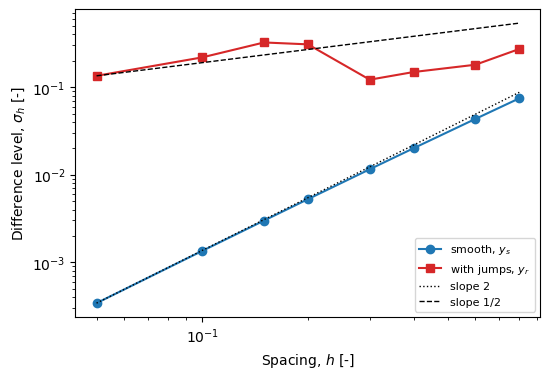

In [4]:
# The scan grid of Parts 3 to 5: 81 points from -2 to 2, a step of 0.05; spacings of 1 to 16 grid steps.
XI_SCAN = np.linspace(-2.0, 2.0, 81)
STEPS = np.array([1, 2, 3, 4, 6, 8, 12, 16])


def difference_level(y, steps):
    """Difference level sigma_h = sqrt(mean((Delta_h^2 y)^2) / 6) of equally spaced values y, for each spacing.

    Parameters
    ----------
    y : array of float
        Output at equally spaced points along a line (NaN where missing).
    steps : array of int
        Spacings h, in grid steps.

    Returns
    -------
    array of float
        sigma_h for each spacing, in the units of y (Moré & Wild, Theorem 2.3, with gamma_2 = 1/6).
    """
    # Second differences y(t+2h) - 2 y(t+h) + y(t) at every position, ignoring stencils that touch a missing point.
    return np.array([np.sqrt(np.nanmean((y[2 * m:] - 2 * y[m:-m] + y[:-2 * m]) ** 2) / 6.0) for m in steps])


# The level of both toys along the scan grid.
h = STEPS * (XI_SCAN[1] - XI_SCAN[0])
fig, ax = plt.subplots(figsize=(6.0, 4.0))
ax.loglog(h, difference_level(y_smooth(XI_SCAN), STEPS), "o-", color="C0", label="smooth, $y_s$")
ax.loglog(h, difference_level(y_rough(XI_SCAN), STEPS), "s-", color="C3", label="with jumps, $y_r$")
# Reference slopes 2 and 1/2 through the first point of each curve.
ax.loglog(h, difference_level(y_smooth(XI_SCAN), STEPS)[0] * (h / h[0]) ** 2, "k:", lw=1, label="slope 2")
ax.loglog(h, difference_level(y_rough(XI_SCAN), STEPS)[0] * (h / h[0]) ** 0.5, "k--", lw=1, label="slope 1/2")
ax.set(xlabel="Spacing, $h$ [-]", ylabel="Difference level, $\\sigma_h$ [-]")
ax.legend(fontsize=8)
plt.show()

The smooth toy follows the line of slope 2 over the whole range, from $3\times10^{-4}$ at $h=0.05$ to about 0.07 at
$h=0.8$. The toy with jumps is of order 0.1&ndash;0.3 at every spacing, hundreds of times above the smooth one at
$h=0.05$, and does not shrink with $h$. It does not follow the line of slope 1/2 neatly either: its jumps are 0.17
apart, about the size of the larger spacings, so the stencil often straddles two. What the plot separates is the first
point: a smooth output has a tiny difference level at the finest spacing, an output with a rough layer does not.

## Part 2 &ndash; What the surrogate leaves unexplained is a rough layer

### Step 1 &ndash; Nearby runs do not share their residuals

The cell reads NB9's accepted training runs as NB10 did, and keeps more of each: besides the two loads, the displacement at the peak $\delta_{ULT}$ and the slope of the curve over the last 0.05 mm before the peak
$\kappa_{peak}$ [N/mm] (Step 2). It then fits order 3 (NB10's surrogate) to $P_{ULT}$ and $\delta_{ULT}$, and order 2 to
$P_{FPF}$, and keeps the residuals, Abaqus minus PCE. Reading the files takes a few minutes.

In [5]:
# NB9's inputs and campaign folder.
INPUT_NAMES = ["E1", "E2", "nu12", "G12", "G23", "X_T", "X_C", "Y_T", "Y_C", "S_L", "S_T",
               "G_fT", "G_fC", "G_mT", "G_mC"]
INPUT_MEANS = np.array([172400.0, 10300.0, 0.32, 5520.0, 3450.0, 2826.5, 1620.0, 65.5, 248.0, 122.0, 122.0,
                        81.5, 106.3, 0.2774, 0.7879])
COV_INPUT, D = 0.1, 15
RUNS9 = Path("../runs/nb09")


def slope_before_peak(r, du=0.05):
    """Mean slope (P_ULT - P(delta_ULT - du)) / du of a run's curve over the last du [mm] before its peak [N/mm]."""
    # The curve up to the peak, and the load du before the peak by linear interpolation.
    u, f, k = np.array(r["u2"]), np.array(r["rf2"]), r["peak_index"]
    return (f[k] - np.interp(u[k] - du, u[:k + 1], f[:k + 1])) / du


def read_runs(design_csv, folder):
    """Standardised inputs and per-run quantities (NaN where rejected) of a campaign."""
    # Inputs, standardised with x = mu (1 + CoV xi).
    with open(design_csv, newline="") as f:
        x = np.array([[float(v) for v in row] for row in list(csv.reader(f))[1:]])
    xi = (x / INPUT_MEANS - 1.0) / COV_INPUT
    q = {k: np.full(len(x), np.nan) for k in ("P_FPF", "P_ULT", "d_ULT", "k_peak")}
    for i in range(len(x)):
        with open(folder / ("s%04d.json" % i)) as f:
            r = drop_failed_frame(json.load(f))
        if acceptance_reason(r):
            continue
        # The loads [N], the peak displacement [mm] and the slope before the peak [N/mm].
        q["P_FPF"][i], q["P_ULT"][i], q["d_ULT"][i] = r["fpf"]["rf2_n"], r["f_peak_n"], r["u2_peak_mm"]
        q["k_peak"][i] = slope_before_peak(r)
    return xi, q

With the reading function defined, the next cell reads all the accepted training runs and fits the surrogates.

In [6]:
# The accepted training runs, and their order-3 (P_ULT, delta_ULT) and order-2 (P_FPF) residuals.
xi_all, q_all = read_runs(RUNS9 / "design_train.csv", RUNS9 / "train")
# Keep the accepted runs (NaN marks a rejected one).
ok = ~np.isnan(q_all["P_ULT"])
xi, q = xi_all[ok], {k: v[ok] for k, v in q_all.items()}
# Order-3 basis for all 15 inputs, and its design matrix at the accepted runs.
alphas_3 = total_order_indices(D, 3)
psi_3 = design_matrix(xi, alphas_3)
coef_ult = fit_pce(xi, q["P_ULT"], alphas_3)
# Residuals (Abaqus minus PCE) of P_ULT [N] and of delta_ULT [mm], from order-3 fits.
res_p = q["P_ULT"] - psi_3 @ coef_ult
res_d = q["d_ULT"] - psi_3 @ fit_pce(xi, q["d_ULT"], alphas_3)
# The same for P_FPF at order 2 [N].
psi_2 = design_matrix(xi, total_order_indices(D, 2))
res_fpf = q["P_FPF"] - psi_2 @ fit_pce(xi, q["P_FPF"], total_order_indices(D, 2))
# Residual size, and the share of the variance it holds.
print("%d accepted runs; P_ULT residual std %.0f N (P_ULT std %.0f N, unexplained share %.3f)"
      % (ok.sum(), res_p.std(), q["P_ULT"].std(), res_p.var() / q["P_ULT"].var()))

12197 accepted runs; P_ULT residual std 794 N (P_ULT std 2330 N, unexplained share 0.116)


The order-3 surrogate leaves a residual of 794 N (rms) on $P_{ULT}$, whose own standard deviation is 2,330 N: 11.6% of
the variance, the same floor as in NB10 and in the toy. That is 2.2% of a typical peak load of about 35 kN.

Is that 11% a rough layer, or the smooth higher-order terms that order 3 leaves out? The shape of the residuals cannot
tell: hundreds of small, smooth leftover terms would also add up to a near-normal histogram.

What does tell the two apart is how the residuals of **nearby** runs compare. If $P_{ULT}$ is smooth, two runs with
almost the same inputs have almost the same residual: the leftover terms are smooth too. If it is rough, their
residuals are unrelated. The **semivariogram**, $\gamma(r)=\tfrac12\,\overline{(e_i-e_j)^2}$ over pairs of runs whose
inputs are a distance $r$ apart in $\boldsymbol\xi$, measures this [units of $e^2$]: divided by the residual variance,
it starts near 0 at small $r$ for a smooth leftover and near 1 for a rough one. The cell computes it for the $P_{ULT}$
residuals and, as a smooth contrast, for those of order 2 of $P_{FPF}$, from all pairs among the first 3,000 accepted
runs, and the correlation of each run's residual with that of its nearest neighbour among all runs.

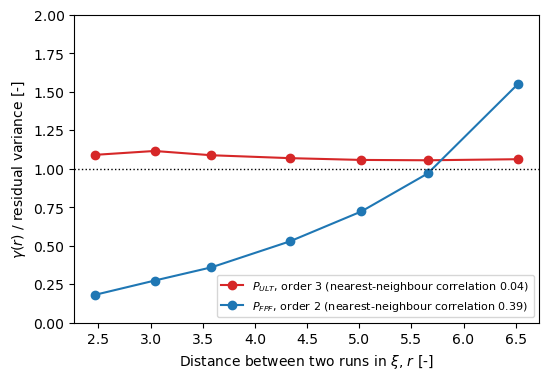

nearest-neighbour distance: median 2.28 (0.59 per input); closest 0.1% of pairs below 2.62


In [7]:
# Pairwise distances in xi among the first 3,000 accepted runs, and the distance of each run to its nearest neighbour.
# The first 3,000 runs, and every pair among them.
sub = np.arange(3000)
iu = np.triu_indices(len(sub), 1)
# Euclidean distance of each pair in the 15-D xi space.
dist = np.sqrt(((xi[sub][:, None, :] - xi[sub][None, :, :]) ** 2).sum(-1))[iu]
nn_dist, nn = cKDTree(xi).query(xi, k=2)
# Column 0 is the run itself; column 1 is its nearest neighbour.
nn_dist, nn = nn_dist[:, 1], nn[:, 1]
# Distance bins with equal numbers of pairs, from the closest 0.1% upwards.
edges = np.percentile(dist, [0, 0.1, 1, 5, 25, 50, 75, 100])
# The median distance in each bin is its x position.
centres = [np.median(dist[(dist >= a) & (dist < b)]) for a, b in zip(edges[:-1], edges[1:])]
# One curve per residual set.
fig, ax = plt.subplots(figsize=(6.0, 4.0))
for e, label, color in ((res_p, "$P_{ULT}$, order 3", "C3"), (res_fpf, "$P_{FPF}$, order 2", "C0")):
    # Semivariogram over the residual variance, per distance bin, and the nearest-neighbour correlation.
    g = 0.5 * (e[sub][iu[0]] - e[sub][iu[1]]) ** 2 / e.var()
    ax.plot(centres, [g[(dist >= a) & (dist < b)].mean() for a, b in zip(edges[:-1], edges[1:])], "o-", color=color,
            label="%s (nearest-neighbour correlation %.2f)" % (label, np.corrcoef(e, e[nn])[0, 1]))
# gamma = variance (1) means unrelated residuals.
ax.axhline(1.0, color="k", ls=":", lw=1)
ax.set(xlabel="Distance between two runs in $\\xi$, $r$ [-]", ylabel="$\\gamma(r)$ / residual variance [-]", ylim=(0, 2.0))
# Legend, then the distances for the record.
ax.legend(fontsize=8, loc="lower right")
plt.show()
print("nearest-neighbour distance: median %.2f (%.2f per input); closest 0.1%% of pairs below %.2f"
      % (np.median(nn_dist), np.median(nn_dist) / np.sqrt(D), edges[1]))

The residual of $P_{ULT}$ (red) is flat at about 1.1 times its variance at every distance: two runs are no more alike
when they are close than when they are far, and a run's residual is almost uncorrelated with that of its nearest
neighbour (0.03). The residual of order 2 of $P_{FPF}$ (blue), the smooth contrast, starts at 0.18 for the nearest pairs
and rises with distance, because its leftover is a smooth function that nearby runs share (neighbour correlation 0.38).
So whatever the order-3 surrogate misses in $P_{ULT}$ varies on a scale smaller than the typical distance between two
runs. The limit is the sampling: the median nearest neighbour is 2.28 away in $\boldsymbol\xi$, 0.59 per input, so
the campaign cannot say how much smaller. In what follows, the **rough layer** is this part of $P_{ULT}$: the part that varies faster than the runs can resolve, and that the surrogate therefore leaves as its unexplained variance. Part 3 asks the model directly, with runs 0.5% apart.

### Step 2 &ndash; Where the rough layer comes from: the timing of the collapse

Every curve of NB9 rises almost in a straight line and then collapses almost vertically, so the peak load is the load
on the rising branch at the displacement where the collapse starts, $\delta_{ULT}$. If the collapse starts a little early
or late, by $\Delta\delta$ [mm], the peak changes by about the slope of the rising branch times $\Delta\delta$. So if the
rough layer is in the **timing** of the collapse, the residuals of $P_{ULT}$ should follow those of $\delta_{ULT}$, with
the slope $\kappa_{peak}$ as the factor. The cell compares them.

delta_ULT residual std 0.0197 mm; correlation with the P_ULT residual 0.963 (squared 0.93); fitted factor 38771 N/mm
slope kappa_peak before the peak: median 39713 N/mm (5th-95th percentile 26225-49546 N/mm)


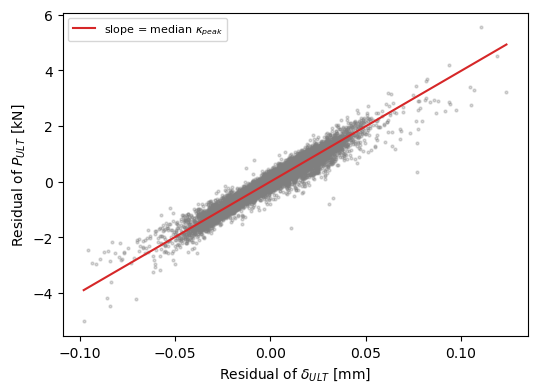

In [8]:
# How closely the two residuals follow each other, the factor between them, and the slope before the peak [N/mm].
corr = np.corrcoef(res_d, res_p)[0, 1]
print("delta_ULT residual std %.4f mm; correlation with the P_ULT residual %.3f (squared %.2f); fitted factor %.0f N/mm"
      % (res_d.std(), corr, corr ** 2, np.polyfit(res_d, res_p, 1)[0]))
print("slope kappa_peak before the peak: median %.0f N/mm (5th-95th percentile %.0f-%.0f N/mm)"
      % (np.median(q["k_peak"]), *np.percentile(q["k_peak"], [5, 95])))
# Plot the dots.
# One dot per run, and the line of slope median kappa_peak through the origin [kN against mm].
fig, ax = plt.subplots(figsize=(6.0, 4.2))
ax.plot(res_d, res_p / 1e3, "o", color="C7", ms=2, alpha=0.3)
d_line = np.array([res_d.min(), res_d.max()])
ax.plot(d_line, np.median(q["k_peak"]) * d_line / 1e3, "C3-", label="slope = median $\\kappa_{peak}$")
ax.set(xlabel="Residual of $\\delta_{ULT}$ [mm]", ylabel="Residual of $P_{ULT}$ [kN]")
ax.legend(loc="upper left", fontsize=8)
plt.show()

The two residuals move together: correlation 0.963, so 93% of the variance of the $P_{ULT}$ residual is carried by that
of $\delta_{ULT}$, which has a standard deviation of 0.0197 mm. The fitted factor, 38,771 N/mm, is within 3% of the
median slope $\kappa_{peak}$ before the peak, 39,713 N/mm (5th to 95th percentile 26,225&ndash;49,546 N/mm), as the
argument predicts. So the rough layer of $P_{ULT}$ is, almost entirely, a rough layer in **when** the collapse starts:
the rising branch itself is smooth, the point where it ends is not. The few dots far from the line are runs where the
slope differs from the median.

## Part 3 &ndash; A line scan along $E_1$

### Step 1 &ndash; 81 runs, 0.5% apart

Part 2 left a question open: is $P_{ULT}$ smooth below the spacing of the campaign, 0.6 standard deviations per input, or
rough? Only runs much closer together can answer it. We place them on a **line** through the nominal point (every input at
its mean) on which only $E_1$ moves, the input with the largest Sobol' index of $P_{ULT}$ (NB10, Part 5), with Part 1's grid:

$$E_1=\mu_{E_1}\,(1+0.1\,t),\qquad t=-2,-1.95,\dots,2,$$

where
- $t$ is the position along the line, the standardised input $\xi_{E_1}$ of NB8 [-],
- $\mu_{E_1}=172.4$ GPa is the mean of $E_1$, and 0.1 its coefficient of variation (NB9) [GPa, -].

So $E_1$ runs from 137.9 to 206.9 GPa in 81 steps of 0.862 GPa, 0.5% of the mean, and from here on the scan is plotted
against $E_1$. The first cell defines the safety switch and two helpers: one writes a design file or checks it against the
one on disk, the other runs the missing results of a scan with NB9's driver (if allowed) and loads all of them.

In [9]:
# Safety switch, NB11's folder, and NB9's driver.
RUN_CAMPAIGN = False
RUNS = Path("../runs/nb11")
DRIVER = Path("../scripts/oht_campaign.py")


def write_or_check_design(path, x):
    """Write a design CSV (full-precision floats), or check that an existing one matches it."""
    if path.exists():
        # Read the file back, skipping the header line, and compare.
        with open(path, newline="") as f:
            on_disk = np.array([[float(v) for v in row] for row in list(csv.reader(f))[1:]])
        assert np.allclose(on_disk, x, rtol=1e-12, atol=0.0), path.name + " differs from the regenerated design"
        return "checked"
    # Otherwise write a header line and one row per run.
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(INPUT_NAMES)
        writer.writerows([[repr(float(v)) for v in row] for row in x])
    return "written"


def run_or_load_scan(design, folder, template_dir=None, template_args=""):
    """Run the missing results of a scan with NB9's driver (if RUN_CAMPAIGN), then load all of them.

    template_dir, template_args : folder of the scan's own template and the build-script settings it is built with if
        missing, e.g. "maxinc=0.001 maxnuminc=50000"; None for NB9's template (maxinc 0.01, runs/nb09/template).
    Returns a dict: results (a failed last frame dropped), ok (accepted), P [N] and d [mm] at the peak (NaN if rejected).
    """
    # The number of design rows, and the results not on disk yet.
    with open(design, newline="") as f:
        n = len(list(csv.reader(f))) - 1
    missing = [i for i in range(n) if not (folder / ("s%04d.json" % i)).exists()]
    # NB9's driver, six jobs at once at most (the desktop's physical cores), with the scan's own template if any.
    command = [sys.executable, str(DRIVER), "--design", str(design), "--out-dir", str(folder), "--workers", "6"]
    if template_dir:
        command += ["--template-dir", str(template_dir), "--template-args", template_args]
    # Run the missing ones if allowed, else print what to run.
    if missing and RUN_CAMPAIGN:
        subprocess.run(command, check=True)
    elif missing:
        print("%d results missing in %s; on a machine with Abaqus run:\n    %s" % (len(missing), folder.name, " ".join(command[1:])))
    # Load every result with its screening verdict, and the peak load and displacement of the accepted ones.
    results = []
    for i in range(n):
        with open(folder / ("s%04d.json" % i)) as f:
            results.append(drop_failed_frame(json.load(f)))
    ok = np.array([acceptance_reason(r) == "" for r in results])
    P = np.array([r["f_peak_n"] if a else np.nan for r, a in zip(results, ok)])
    d = np.array([r["u2_peak_mm"] if a else np.nan for r, a in zip(results, ok)])
    return {"results": results, "ok": ok, "P": P, "d": d}

The next cell builds the 81 inputs of the scan, writes or checks its design file, and loads its results, solved with NB9's
template (the increment cap `maxinc` = 0.01 of NB6 and NB9).

In [10]:
# The inputs along the line: E1 = mu_E1 (1 + CoV t), the 14 other inputs at their means [input units].
x_a = INPUT_MEANS * (1.0 + COV_INPUT * XI_SCAN[:, None] * np.eye(D)[INPUT_NAMES.index("E1")])
# E1 along the line [GPa], the x axis of every scan plot.
E1_GPA = x_a[:, 0] / 1e3
design_a = RUNS / "design_scan_a.csv"
print("design_scan_a.csv: %s; E1 from %.1f to %.1f GPa in steps of %.3f GPa"
      % (write_or_check_design(design_a, x_a), E1_GPA[0], E1_GPA[-1], E1_GPA[1] - E1_GPA[0]))
# One scan per increment cap; this Part uses NB9's cap 0.01 (its template, in runs/nb09/template).
scan = {0.01: run_or_load_scan(design_a, RUNS / "scan_a")}
print("maxinc 0.01: %d of 81 runs accepted" % scan[0.01]["ok"].sum())

design_scan_a.csv: checked; E1 from 137.9 to 206.9 GPa in steps of 0.862 GPa


maxinc 0.01: 81 of 81 runs accepted


All 81 runs are accepted: each has a first-ply failure and a load drop of at least 20% after its peak (NB9's screening).

### Step 2 &ndash; The peak load along $E_1$

The cell draws $P_{ULT}$ against $E_1$, with the order-3 surrogate of Part 2 along the same line: the
trend the surrogate sees.

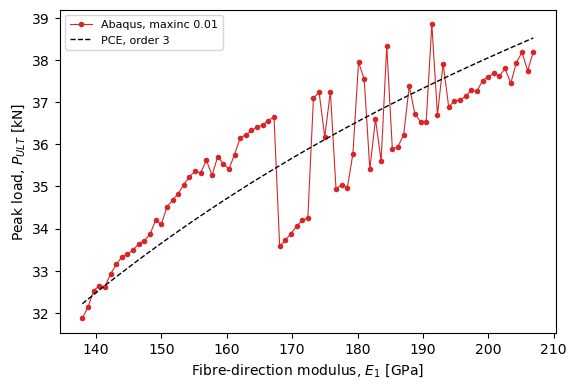

P_ULT 31.9-38.9 kN; largest change between neighbours 3073 N (E1 = 167.23 -> 168.09 GPa); rms Abaqus - PCE 954 N


In [11]:
# The order-3 surrogate along the line [N].
pce_a = design_matrix(XI_SCAN[:, None] * np.eye(D)[INPUT_NAMES.index("E1")], alphas_3) @ coef_ult
s = scan[0.01]  # the scan with NB9's cap
# P_ULT and the surrogate [kN] against E1 [GPa].
fig, ax_p = plt.subplots(figsize=(6.4, 4.2))
ax_p.plot(E1_GPA, s["P"] / 1e3, "o-", color="C3", ms=3, lw=0.8, label="Abaqus, maxinc 0.01")
ax_p.plot(E1_GPA, pce_a / 1e3, "k--", lw=1, label="PCE, order 3")
ax_p.set(xlabel="Fibre-direction modulus, $E_1$ [GPa]", ylabel="Peak load, $P_{ULT}$ [kN]")
ax_p.legend(fontsize=8)
plt.show()
# The largest change between two neighbouring runs, and the rms difference from the surrogate [N].
jumps = np.abs(np.diff(s["P"]))
k = int(np.nanargmax(jumps))  # the first run of the largest change is k, the second k + 1
print("P_ULT %.1f-%.1f kN; largest change between neighbours %.0f N (E1 = %.2f -> %.2f GPa); rms Abaqus - PCE %.0f N"
      % (np.nanmin(s["P"]) / 1e3, np.nanmax(s["P"]) / 1e3, jumps[k], E1_GPA[k], E1_GPA[k + 1],
         np.sqrt(np.nanmean((s["P"] - pce_a) ** 2))))

For $E_1$ up to 167.2 GPa, $P_{ULT}$ rises smoothly with $E_1$, from 31.9 to 36.7 kN, and the displacement at the peak, $\delta_{ULT}$ (not drawn: it moves with $P_{ULT}$, Part 2), falls slowly
from about 0.74 to 0.71 mm. Then, between two neighbouring runs 0.86 GPa apart (167.23 and 168.09 GPa), $P_{ULT}$ drops by
3,073 N, from 36.7 to 33.6 kN, and $\delta_{ULT}$ drops with it, to 0.64 mm. Beyond the drop the output no longer has one
trend. It runs smoothly for a few runs (33.6 to 34.3 kN up to the nominal 172.4 GPa, with $\delta_{ULT}$ between 0.639 and
0.641 mm), then jumps up (37.1 kN at 173.3 GPa, $\delta_{ULT}$ back at 0.706 mm), and so on: jumps of 1 to 3 kN, up and down,
every few runs, each with its jump in $\delta_{ULT}$ (about 0.07 mm for a jump of 3 kN). The surrogate (dashed) passes through the middle of this scatter; the
rms difference between Abaqus and the surrogate along the line is 954 N, a little above the campaign's 794 N.

### Step 3 &ndash; How rough is it, and where does it start?

Now Part 1's measure on the scan: the difference level $\sigma_h$ against the spacing, here a step $\Delta E_1$ in GPa. Two
loads of the same runs serve as contrasts, both set by the Hashin criteria of [NB1](01_fiber_tension_single_element.ipynb)
alone: $P_{FPF}$, where the first criterion is met anywhere, and the load at the first fibre failure in a 0° ply, the moment
the fibres start to break. If the rough layer came from the criteria, for example from the corners where two of them meet,
these two loads would be rough as well. The cell also lists which mode and ply start first-ply failure along the line.

P_{ULT}                          sigma_h = 6.3e+02, 6.9e+02, 8.4e+02, 9.1e+02, 1e+03, 8e+02, 9.6e+02, 1.1e+03 N
load at first 0° fibre failure   sigma_h = 5.7, 6.7, 8.4, 10, 12, 16, 32, 49 N
P_{FPF}                          sigma_h = 0.00024, 0.0008, 0.0018, 0.0031, 0.007, 0.012, 0.027, 0.048 N


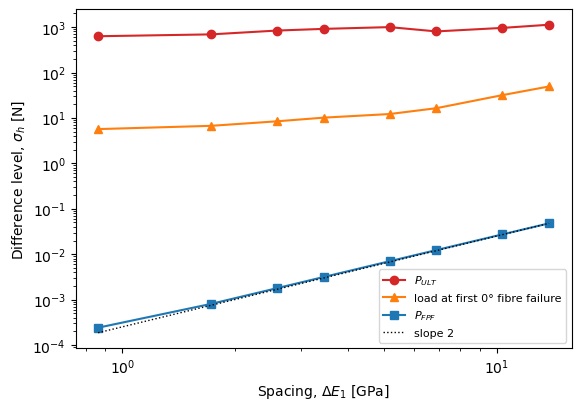

spacings: 0.86, 1.72, 2.59, 3.45, 5.17, 6.90, 10.34, 13.79 GPa
first-ply failure (mode, ply): [('matrix tension', 4)]


In [12]:
# The spacings of Part 1 in GPa of E1, and the loads of the accepted runs [N] (NaN for a rejected one).
dE1 = STEPS * (E1_GPA[1] - E1_GPA[0])
runs_a = [r if a else None for r, a in zip(s["results"], s["ok"])]
fpf_a = np.array([r["fpf"]["rf2_n"] if r else np.nan for r in runs_a])
onset_a = np.array([r["onset0"]["rf2_n"] if r else np.nan for r in runs_a])
# The difference level of the three loads, one curve each, and a slope-2 reference through the last point of P_FPF.
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for y, label, marker, color in ((s["P"], "$P_{ULT}$", "o-", "C3"), (onset_a, "load at first 0° fibre failure", "^-", "C1"),
                                (fpf_a, "$P_{FPF}$", "s-", "C0")):
    # Part 1's difference level at each spacing [N], on log-log axes, and printed.
    lev = difference_level(y, STEPS)
    ax.loglog(dE1, lev, marker, color=color, label=label)
    print("%-32s sigma_h = %s N" % (label.replace("$", ""), ", ".join("%.2g" % v for v in lev)))
ax.loglog(dE1, difference_level(fpf_a, STEPS)[-1] * (dE1 / dE1[-1]) ** 2, "k:", lw=1, label="slope 2")
# Axis labels, legend, figure, and the spacings in GPa.
ax.set(xlabel=r"Spacing, $\Delta E_1$ [GPa]", ylabel=r"Difference level, $\sigma_h$ [N]")
ax.legend(fontsize=8)
plt.show()
print("spacings: %s GPa" % ", ".join("%.2f" % v for v in dE1))
# Which mode and ply start first-ply failure along the line (one entry if it never changes).
print("first-ply failure (mode, ply): %s" % sorted({(r["fpf"]["mode"], r["fpf"]["ply"]) for r in runs_a if r}))

For $P_{ULT}$ the difference level is 629 N at the finest spacing and only about doubles over a spacing 16 times larger
(1,127 N at 13.8 GPa): nearly flat, the signature of jumps closer together than the spacing (Part 1, Step 2), and of the
size of the campaign's residual (794 N). $P_{FPF}$ follows the slope-2 line from 0.00024 N: smooth. The load at the first 0°
fibre failure lies in between, 5.7 N at the finest spacing and rising slowly, a hundred times below $P_{ULT}$. First-ply
failure is matrix tension in ply 4 (a 90° ply) in all 81 runs.

So the moments that the criteria set where the damage *starts* move smoothly with $E_1$, and no switch between criteria
shows up in them. The roughness appears later, between the first 0° fibre failure (at about 26.5 kN) and the peak, where the
damage grows and spreads from element to element, and where the solver has to follow it increment by increment. Step 4 looks at what the damage does in that stretch.

### Step 4 &ndash; What the damage does between the first 0° fibre failure and the peak

The scan runs keep only what the surrogate needs. To see where the damage goes, the cell repeats six of them with NB6's
build script in full mode (`light=0`), which also writes the mesh and the damage of every element, ply and mode at chosen
frames (Abaqus/CAE, 5 to 15 minutes each on the desktop), or loads them. The six points, A to F in order of $E_1$: a
run at low $E_1$ (155.2 GPa, A); the two runs either side of the largest drop, 167.23 and 168.09 GPa (B, C); a run that
jumps up, 184.47 GPa, with its right neighbour, back down (D, E); and a run at high $E_1$ (202.6 GPa, F). The model is deterministic, so each full run should reproduce its scan run; the cell checks it.

In [13]:
# NB6's build script, which builds, solves and reads one model in Abaqus/CAE.
BUILD = Path("../scripts/build_open_hole_tension.py")
# Besides first-ply failure, the first 0-deg fibre failure and the peak, the full runs tabulate the damage at these applied
# displacements [mm]: every 0.005 mm where the paths part (Part 5), and later.
FRAME_U2 = [0.50] + [round(0.540 + 0.005 * k, 3) for k in range(17)] + [0.63, 0.64, 0.65, 0.66, 0.68, 0.69, 0.71, 0.72, 0.75]


def full_run(name, x, maxinc):
    """Run-or-load a full-output run of NB6's build script (mesh M1) with inputs x and increment cap maxinc.

    Returns (mesh, damage rows grouped by frame tag, result). The frame tags are "onset0" (first 0-deg fibre failure), "peak", and "u<displacement>" for FRAME_U2.
    """
    # The run's result file, in runs/nb11/full.
    out = RUNS / "full" / (name + ".json")
    # The build script's arguments: mesh M1, full output, the cap, the damage frames, the 15 inputs by name, G13 = G12.
    inputs = dict(zip(INPUT_NAMES, x))
    args = ["ncirc=20", "nrad=15", "light=0", "maxinc=%g" % maxinc, "maxnuminc=50000",
            "damage_u2=" + ",".join("%.3f" % u for u in FRAME_U2)]
    args += ["%s=%r" % (n.lower(), float(v)) for n, v in inputs.items()] + ["g13=%r" % float(inputs["G12"]), "out=" + out.resolve().as_posix()]
    # Run with this kernel's Python, which hands the script to Abaqus/CAE.
    command = [sys.executable, str(BUILD.resolve())] + args
    # Run it if allowed, or print the command for a machine with Abaqus.
    if not out.exists() and RUN_CAMPAIGN:
        subprocess.run(command, cwd=str(out.parent))
    elif not out.exists():
        print("missing %s; run from %s:\n    %s" % (out.name, out.parent, " ".join(command[1:])))
    # The result (a failed last frame dropped), the damage table grouped by frame tag, and the mesh.
    with open(out) as f:
        result = drop_failed_frame(json.load(f))
    rows = {}
    with open(RUNS / "full" / (name + "_damage.csv"), newline="") as f:
        # One row per damaged element and ply at each tabulated displacement.
        for row in csv.DictReader(f):
            rows.setdefault(row["frame_tag"], []).append(row)
    # Node coordinates and element connectivity of mesh M1, for the maps.
    with open(RUNS / "full" / (name + "_mesh.json")) as f:
        mesh = json.load(f)
    return mesh, rows, result


# The six points of the scan, A to F in order of E1 (row numbers of scan A).
POINTS = {"A": 20, "B": 34, "C": 35, "D": 54, "E": 55, "F": 75}
# Each point in full mode with NB9's cap.
coarse = {i: full_run("a%02d_inc010" % i, x_a[i], 0.01) for i in POINTS.values()}
for name, i in POINTS.items():
    # Peak load [N] and displacement [mm] of the full run, against the scan run with the same cap.
    res = coarse[i][2]
    print("%s: E1 = %.2f GPa; full run P_ULT %.1f N at %.4f mm; scan run %.1f N at %.4f mm"
          % (name, E1_GPA[i], res["f_peak_n"], res["u2_peak_mm"], scan[0.01]["P"][i], scan[0.01]["d"][i]))

A: E1 = 155.16 GPa; full run P_ULT 35358.2 N at 0.7389 mm; scan run 35358.2 N at 0.7389 mm
B: E1 = 167.23 GPa; full run P_ULT 36655.3 N at 0.7097 mm; scan run 36655.3 N at 0.7097 mm
C: E1 = 168.09 GPa; full run P_ULT 33582.8 N at 0.6401 mm; scan run 33582.8 N at 0.6401 mm
D: E1 = 184.47 GPa; full run P_ULT 38334.4 N at 0.6882 mm; scan run 38334.4 N at 0.6882 mm
E: E1 = 185.33 GPa; full run P_ULT 35878.9 N at 0.6260 mm; scan run 35878.9 N at 0.6260 mm
F: E1 = 202.57 GPa; full run P_ULT 37806.0 N at 0.6075 mm; scan run 37806.0 N at 0.6075 mm


All six full runs reproduce their scan runs to the last printed digit, from 33,582.8 N at 0.6401 mm (C) to 38,334.4 N at
0.6882 mm (D). Same inputs and same cap, same answer: the scatter of the scan is not noise in the solver's arithmetic.

The next cell defines three functions. `damage_map` colours each element of the mesh by the damage of one tabulated frame,
`stage_tags` picks three frames of each run, and `damage_figure` draws one figure with them. On top, the scan of Step 2 with
the six points circled. Below, one column per point: the fibre-tension damage of the 0° plies (plies 2 and 7, the larger of
the two in each element) at three moments of the run: halfway from the first 0° fibre failure to the peak, the peak, and an
applied displacement of 0.75 mm, after every run has collapsed. The first two rows are a close view of the hole's right edge;
the last shows the whole right half of the plate's width, out to the free edge. The colour is the fibre-tension damage variable,
from 0 (none) to 1 (no stiffness left).

In [14]:
def damage_map(ax, mesh, rows, column, plies, xlim, ylim, highlight=()):
    """Colour each element by the largest damage `column` over `plies` in the tabulated `rows` of one frame;
    the elements whose labels are in `highlight` get a blue outline."""
    # Element outlines from the mesh file: the node coordinates [mm], and one polygon per element.
    nodes = np.array(mesh["nodes"])  # node coordinates [mm]
    polys = [nodes[e] for e in mesh["elements"]]
    # The damage of each element, 0 where the table has no row (undamaged), and the largest over the plies asked for.
    value = dict.fromkeys(mesh["labels"], 0.0)
    for row in rows:
        # Keep the row if its ply is one of those asked for, and the largest damage of its element.
        if int(row["ply"]) in plies:
            lab = int(row["element_label"])
            value[lab] = max(value[lab], float(row[column]))
    # The collection of coloured polygons, the damage variable on a scale from 0 to 1.
    pc = PolyCollection(polys, array=np.array([value[l] for l in mesh["labels"]]), cmap="Reds",
                        edgecolors="0.6", linewidths=0.2, clim=(0, 1))
    ax.add_collection(pc)
    # Outline the highlighted elements (by label) in blue.
    for lab in highlight:
        ax.add_patch(plt.Polygon(nodes[mesh["elements"][mesh["labels"].index(lab)]], fill=False, edgecolor="tab:blue", lw=1.6))
    # Intact material is near-white in this colour map and the hole is white: draw the hole's edge.
    ax.add_patch(plt.Circle((38.1, 38.1), 9.525, fill=False, color="k", lw=0.8))
    # The view: the hole is centred at x = y = 38.1 mm with radius 9.525 mm, so its right edge is at x = 47.6 mm.
    ax.set(xlim=xlim, ylim=ylim, aspect="equal", xticks=[], yticks=[])
    return pc


def stage_tags(res, frame_u2):
    """Frame tags of three moments of a full run: the frame_u2 entry nearest halfway from the first 0-deg fibre failure
    to the peak, the peak, and 0.75 mm."""
    # Applied displacement at the first 0-deg fibre failure [mm], and the tabulated displacement nearest halfway to the peak.
    u_onset = res["u2"][res["tagged_frames"]["onset0"]]
    half = min(frame_u2, key=lambda u: abs(u - 0.5 * (u_onset + res["u2_peak_mm"])))
    return ["u%.4f" % half, "peak", "u0.7500"]


def damage_figure(points, runs, e1, load, frame_u2, colors=None, legend=None):
    """The scan on top and, below it, the 0-deg fibre-tension damage of the full runs at the labelled points.

    points : {label: row of the scan};  runs : {row: (mesh, damage rows by frame tag, result)} of those points
    e1, load : E1 [GPa] and P_ULT [N] along the scan;  frame_u2 : the tabulated displacements [mm]
    colors : one colour per scan run for the dots (default red);  legend : {name: colour} for those colours.
    """
    # The rows of maps: name, and view [mm]. Before and at the peak a close view of the hole's right edge (x = 47.6 mm);
    # after the collapse the whole right ligament, out to the free edge at x = 76.2 mm.
    close, wide = dict(xlim=(46.8, 56.0), ylim=(33.0, 43.2)), dict(xlim=(46.8, 76.6), ylim=(22.0, 54.2))
    stages = [("halfway to\nthe peak", close), ("peak", close), ("0.75 mm,\nafter collapse", wide)]
    fig = plt.figure(figsize=(13.0, 11.0), layout="constrained")
    grid = fig.add_gridspec(1 + len(stages), len(points), height_ratios=[1.6, 1.0, 1.0, 1.0])
    # Top: the scan [kN against GPa] as a grey line with one dot per run, and the labelled points circled.
    ax = fig.add_subplot(grid[0, :])
    ax.plot(e1, load / 1e3, "-", color="0.7", lw=0.8)
    ax.scatter(e1, load / 1e3, c=colors if colors is not None else "C3", s=14, zorder=3)
    for name, i in points.items():
        ax.plot(e1[i], load[i] / 1e3, "o", color="k", ms=9, mfc="none")
        ax.annotate(name, (e1[i], load[i] / 1e3), xytext=(0, 9), textcoords="offset points", ha="center", fontweight="bold")
    ax.set(xlabel="Fibre-direction modulus, $E_1$ [GPa]", ylabel="Peak load, $P_{ULT}$ [kN]")
    # A legend for the colours, if they carry a meaning.
    if legend:
        ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=n) for n, c in legend.items()], fontsize=8)
    # Below: one column per point, one row per moment; each title gives the frame's applied displacement and load.
    map_axes = []
    for col, (name, i) in enumerate(points.items()):
        mesh, rows_by_tag, res = runs[i]
        for row, (tag, (stage, view)) in enumerate(zip(stage_tags(res, frame_u2), stages)):
            a = fig.add_subplot(grid[1 + row, col])
            map_axes.append(a)
            k = res["tagged_frames"][tag]
            pc = damage_map(a, mesh, rows_by_tag[tag], "damage_ft", (2, 7), **view)
            a.set_title(("%s: %.2f GPa\n" % (name, e1[i]) if row == 0 else "") + "%.3f mm, %.1f kN" % (res["u2"][k], res["rf2"][k] / 1e3),
                        fontsize=8)
            if col == 0:
                a.set_ylabel(stage, fontsize=8)
    # One colour bar for all the maps.
    fig.colorbar(pc, ax=map_axes, shrink=0.5, label="Fibre-tension damage variable [-]")
    plt.show()

The next cell draws the figure for these runs, with NB9's cap.

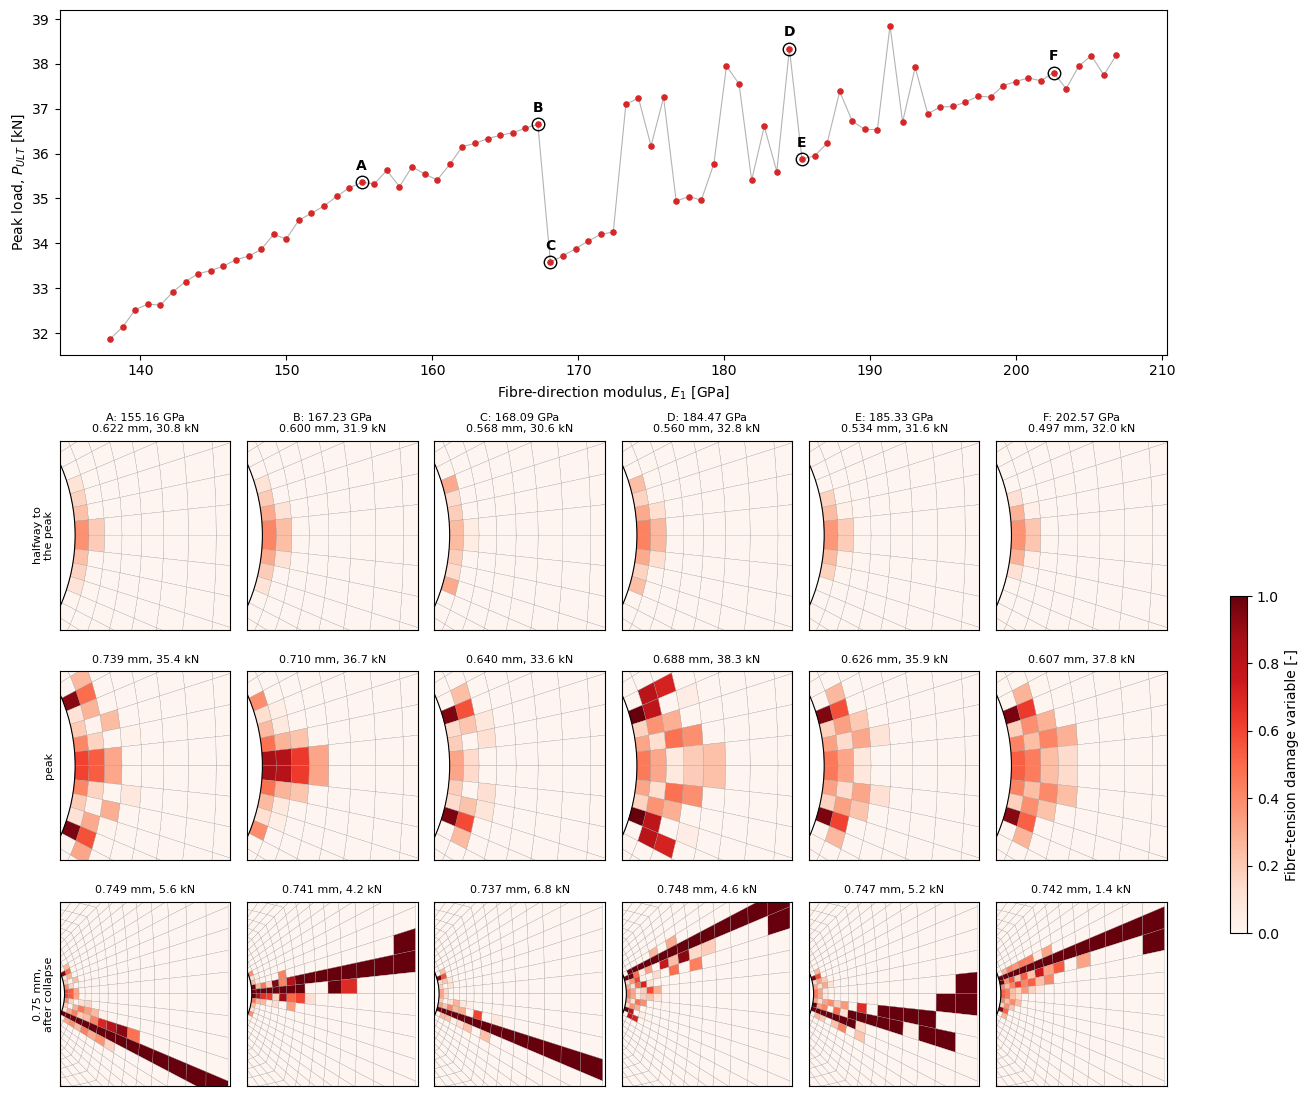

In [15]:
# Six points with NB9's cap: the scan on top, the damage maps of the full runs below.
damage_figure(POINTS, coarse, E1_GPA, scan[0.01]["P"], FRAME_U2)

The runs start alike and end differently. Halfway to the peak (first row) the damage is of one kind in all six: a few
elements on the net section (the line through the hole's centre across the load) at 0.2&ndash;0.5, and a little more at the
hole's edge about 16° above and below it. By the peak (second row) two places have separated. In B the net-section block has
taken the damage (about 0.8, three elements deep) and the two off-axis elements stay light. In the other five the off-axis
elements are near 1 and the block holds less (0.2&ndash;0.6); D has the most spread, with four off-axis elements broken.

After the collapse (third row) each run has broken along a band of elements that leaves the hole from one of these places,
along a radial row of the mesh. The bands do not sort the runs into late and early. A (0.739 mm, 35.4 kN) and D (0.688 mm,
38.3 kN) collapse late, yet their bands are inclined, downwards in A and upwards in D. C, E and F collapse early
(0.607&ndash;0.640 mm), and their bands are inclined too: downwards in C and E, upwards in F. Only B, which also collapses
late (0.710 mm), starts straight along the net section, and its band turns upwards about halfway to the free edge. So with
NB9's cap a late collapse is not a horizontal one, and no run shows a crack that stays on the midline all the way.

Where the plate breaks also changes between neighbours: B and C, 0.86 GPa apart, peak at 36.7 and 33.6 kN, one with its
damage on the net section and one with its damage at the hole's edge. Is that the model or the solver? Part 4 explains how
the solver can do it, and Part 5 repeats these runs with smaller increments to see what the model itself does.

## Part 4 &ndash; The solver's increments

### Step 1 &ndash; Several equilibrium paths, and the increments pick one

Why can two plates 0.5% apart in $E_1$ break in different places? While every point of a body is elastic, or hardening,
the stress fixes the strain and the equilibrium equations have one solution. Once the stress at some point reaches the peak
of a softening law, uniqueness is lost: besides the solution in which all softening points go on together, infinitely many
others satisfy equilibrium, with damage growing in some parts while the rest unload
([Jirásek & Bauer, 2012, p. 63](https://doi.org/10.1016/j.compstruc.2012.06.006)). On a mesh, the most localised of them
softens one element while all the others unload, and it dissipates the least energy. Which solution a computation finds is
decided by small differences: Jirásek and Bauer obtain the localised one by making one integration point slightly weaker
(p. 64). [Santana et al. (2026, p. 13)](https://doi.org/10.1007/s11831-026-10744-y) list such non-unique equilibrium paths
among the reasons why progressive-damage outputs are non-smooth.

Step 4 showed this in the plate. Between the first 0° fibre failure and the peak, the block on the net section and the two
elements 16° from it soften at the same time. In each run one of them pulls ahead, sheds its load and unloads the others,
and the crack then runs through it. Neighbouring runs end with different winners.

What is the small difference here? Nothing random: the full runs of Step 4 repeat their scan runs to the last digit. Our
reading, not a source's: Abaqus moves the loaded edge in increments and finds the damage of every softening element at the
end of each, all together. NB6 capped the increments at `maxinc` = 0.01 of the step, 0.013 mm of $U_2$. An increment that
is long compared with the gap between two softening events can find them in another order than a continuous loading would,
and so play the part of Jirásek and Bauer's weaker point; a 0.5% change of $E_1$ moves where the increments fall against
those events. The viscous regularisation does not prevent it: it makes the tangent stiffness positive definite only for
sufficiently small time increments ([Lapczyk & Hurtado, 2007, p. 2337](https://doi.org/10.1016/j.compositesa.2007.01.017)),
and an increment of 0.01 of the step is 100 times its relaxation time, $\eta=10^{-4}$.

So the paths all satisfy equilibrium, but they are not equally good answers. The path the model means is the one of a
continuous loading, which ever smaller increments approach. If the jumps come from the increments, they should shrink as
the cap shrinks. NB6 converged the cap, but at the nominal inputs only: there, the cap 0.01 gives a peak 1.2% below the cap
0.001. Step 2 tests the whole line.

### Step 2 &ndash; The same line with smaller increments

The cell solves the scan again with `maxinc` = 0.002 and 0.001 (NB9's driver with a template of its own for each cap, built
with room for more increments, `maxnuminc=50000`; at most six jobs at a time, 6 to 13 minutes per job) or loads it, and draws
the peak load of the three caps together.

maxinc 0.002: 81 of 81 runs accepted


maxinc 0.001: 80 of 81 runs accepted


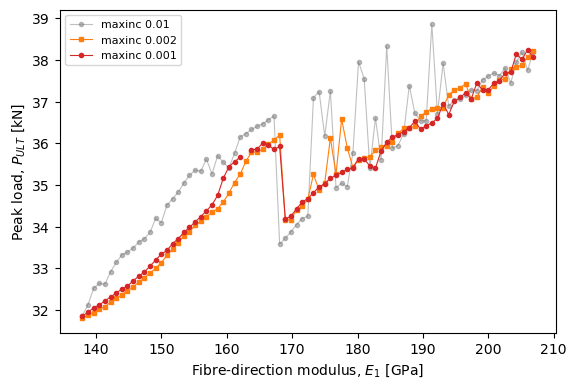

maxinc 0.01  sigma_h =  629,  691,  838,  913 N at dE1 = 0.86, 1.72, 2.59, 3.45 GPa; 16 changes above 1 kN; largest 3073 N (E1 167.23 -> 168.09 GPa)
maxinc 0.002 sigma_h =  231,  257,  313,  388 N at dE1 = 0.86, 1.72, 2.59, 3.45 GPa;  3 changes above 1 kN; largest 2036 N (E1 168.09 -> 168.95 GPa)
maxinc 0.001 sigma_h =  146,  193,  244,  277 N at dE1 = 0.86, 1.72, 2.59, 3.45 GPa;  1 changes above 1 kN; largest 1738 N (E1 168.09 -> 168.95 GPa)
rms change of P_ULT from maxinc 0.01 to 0.002: 968 N
rms change of P_ULT from maxinc 0.002 to 0.001: 280 N


In [16]:
# The scan with the two smaller caps, each with its own template (built by the driver from these settings).
# The templates are shared with the other scans of the same cap: runs/nb11/inc_002 and inc_001.
for cap, name in ((0.002, "scan_a_fine"), (0.001, "scan_a_finest")):
    scan[cap] = run_or_load_scan(design_a, RUNS / name, RUNS / ("inc_%03d" % round(cap * 1000)) / "template",
                                 "maxinc=%g maxnuminc=50000" % cap)
    # How many of the 81 runs pass NB9's screening.
    print("maxinc %g: %d of 81 runs accepted" % (cap, scan[cap]["ok"].sum()))
CAPS = [0.01, 0.002, 0.001]  # the three increment caps, coarsest first
# P_ULT [kN] against E1 [GPa], one line per cap.
fig, ax_p = plt.subplots(figsize=(6.4, 4.2))
for cap, color, marker, alpha, layer in zip(CAPS, ("0.45", "C1", "C3"), ("o", "s", "o"), (0.45, 1.0, 1.0), (1, 2, 3)):
    # NB9's cap in faded grey, behind the others; 0.002 in orange; 0.001 in red, in front.
    ax_p.plot(E1_GPA, scan[cap]["P"] / 1e3, marker + "-", color=color, ms=3, lw=0.8, alpha=alpha, zorder=layer,
              label="maxinc %g" % cap)
# Axis labels, a legend, and the figure.
ax_p.set(xlabel="Fibre-direction modulus, $E_1$ [GPa]", ylabel="Peak load, $P_{ULT}$ [kN]")
ax_p.legend(fontsize=8)
plt.show()
for cap in CAPS:
    # Difference level at the four finest spacings, the largest change between neighbours, and how many exceed 1 kN [N].
    P = scan[cap]["P"]
    # The changes between neighbouring runs [N], and where the largest one is.
    steps_ = np.abs(np.diff(P))
    k = int(np.nanargmax(steps_))
    print("maxinc %-5g sigma_h = %s N at dE1 = %s GPa; %2d changes above 1 kN; largest %.0f N (E1 %.2f -> %.2f GPa)"
          % (cap, ", ".join("%4.0f" % v for v in difference_level(P, STEPS[:4])), ", ".join("%.2f" % v for v in dE1[:4]),
             np.sum(steps_ > 1000), steps_[k], E1_GPA[k], E1_GPA[k + 1]))
# How much the peak moves from one cap to the next, over the whole line (rms) [N].
for a, b in zip(CAPS[:-1], CAPS[1:]):
    print("rms change of P_ULT from maxinc %g to %g: %.0f N" % (a, b, np.sqrt(np.nanmean((scan[b]["P"] - scan[a]["P"]) ** 2))))

The repeated jumps belong to the cap. With `maxinc` = 0.002 (orange; NB9's 0.01 is the faded grey line) the line is much quieter: three changes above 1 kN
instead of 16, and a difference level of 231 N instead of 629 N. With 0.001 (red) only **one** jump is left, a drop of
1,738 N between $E_1$ = 168.09 and 168.95 GPa, the same place where the 0.002 line drops by 2,036 N. On either side of it the
red line is smooth. $\delta_{ULT}$ (not drawn) shows the same two branches: a late collapse (0.69&ndash;0.73 mm) left
of the drop and an early one (0.60&ndash;0.65 mm) right of it. From one cap to the next the peak moves by an rms 968 N (0.01 to
0.002), then 280 N (0.002 to 0.001), mostly from the few runs that still jump at 0.002 (around 173&ndash;178 GPa). One run
of the finest scan (162.92 GPa) is missing: Abaqus stopped it at $U_2$ = 0.32 mm, long before the peak, because one
increment would not converge after six ever smaller attempts ("too many attempts", with warnings of a matrix that is not
positive definite), and it does the same when rerun. The same input converges with the two coarser caps. NB9's screening
rejects such a run, and the statistics here skip it.

The last jump survives the refinement from 0.002 to 0.001 and stays between the same two runs (with NB9's cap it sat
one run further left, Part 5), so it belongs to the model, not to the solver. Whether 0.001 is converged everywhere is not proven by three caps, but the steps from cap to cap shrink fast.

Two more numbers complete the picture. The cell splits the finest scan at its drop and computes each cap's difference level
on the two sides separately. It also measures how far NB9's cap puts the peak from the finest one where neither has
dropped yet: a bias, as opposed to scatter.

In [17]:
# The first run after the drop of the finest scan, and the two sides of it.
cut = int(np.nanargmax(np.abs(np.diff(scan[0.001]["P"])))) + 1
for name, sl in (("left of the drop", slice(0, cut)), ("right of the drop", slice(cut, 81))):
    # Difference level of each cap on this side, at the four finest spacings [N].
    for cap in CAPS:
        print("%-18s maxinc %-5g sigma_h = %s N" % (name, cap, ", ".join("%4.0f" % v for v in difference_level(scan[cap]["P"][sl], STEPS[:4]))))
# How much higher NB9's cap puts the peak than the finest one, before the drop of either cap (NB9's drops one run earlier) [N].
cut_01 = int(np.nanargmax(np.abs(np.diff(scan[0.01]["P"])))) + 1
left = slice(0, min(cut, cut_01))
bias = scan[0.01]["P"][left] - scan[0.001]["P"][left]
print("maxinc 0.01 minus 0.001, E1 up to %.2f GPa: mean %.0f N (from %.0f to %.0f N)"
      % (E1_GPA[left][-1], np.nanmean(bias), np.nanmin(bias), np.nanmax(bias)))

left of the drop   maxinc 0.01  sigma_h =  250,  258,  269,  314 N
left of the drop   maxinc 0.002 sigma_h =   23,   48,   74,  104 N
left of the drop   maxinc 0.001 sigma_h =   33,   61,   81,  123 N
right of the drop  maxinc 0.01  sigma_h =  798,  847, 1025, 1015 N
right of the drop  maxinc 0.002 sigma_h =  252,  206,  231,  319 N
right of the drop  maxinc 0.001 sigma_h =  108,  113,  135,  131 N
maxinc 0.01 minus 0.001, E1 up to 167.23 GPa: mean 718 N (from -27 to 1247 N)


On each side of the drop the finest cap leaves little roughness: a difference level of 33 N on the left and 108 N on the
right, against 250 and 798 N with NB9's cap. The left side is already smooth at 0.002 (23 N); the right side needs 0.001
(252 N at 0.002). And where both caps collapse late (up to 167.2 GPa), NB9's cap does not just scatter the peak around
the converged value: it puts it 0.7 kN higher on average, by up to 1.2 kN (the difference ranges from −0.03 to 1.25 kN). NB9's whole
campaign used that cap, so its peak loads carry this bias as well as the scatter. NB6 found the cap 0.01 to give a peak
1.2% *below* the cap 0.001 at the nominal point (172.4 GPa, right of the drop); along the line the sign of the error changes
with $E_1$, so no single correction would remove it.

> **Pitfall:** a solver setting converged at one input point is not converged over the input distribution. NB6's cap
> check was right at the nominal inputs and still left most of the roughness in NB9's campaign.

## Part 5 &ndash; Two ways to break the plate

### Step 1 &ndash; Which way does each run break?

With NB9's cap the bands of broken 0° elements leave the hole along different mesh rows, and neither timing nor band sorts
the runs. With the finest cap the picture should be the model's own. The cell repeats Part 3's points in full mode with
`maxinc` = 0.001 (Abaqus/CAE, 5 to 15 minutes each) or loads them, checks each against its scan run, and draws Part 3's
figure again. A, D, E and F keep their inputs. B and C follow the drop, which with the finest cap lies one run further
right (Part 4, Step 2): B is now 168.09 GPa (Part 3's C) and C is 168.95 GPa.

Two collapse paths will matter: a band of broken 0° elements straight across the plate along the **midline** (the net
section, the line through the hole's centre across the load), or an **inclined** band leaving the hole's edge at an angle.
Both are 0° fibre-tension failures of the net section; they differ in the path of the crack, so we call them collapse paths
rather than failure modes, a word that for composites usually means fibre, matrix or delamination.

The 81 scan runs do not store damage maps, but they store the order in which the 0° elements reach the fibre-tension
criterion (`ft0_init_order`, element and frame), and the mesh gives each element's position. The elements that reach it just
after the peak are the ones the collapse runs through. The cell labels each run by their median angle from the net section,
seen from the hole's centre, keeping only elements more than 12 mm from the centre (beyond the three rings of elements at the
hole's edge, which fail mostly before the peak): **midline** below 6°, **inclined** above. The mesh's radial
rows of elements sit near 3°, 8°, 13°, 18° and 22°, so 6° separates the midline row from all the others. The dots of the top
panel are coloured by that label, and from here on green and purple mean midline and inclined in every plot, and nothing else.

A: E1 = 155.16 GPa; full run P_ULT 34115.1 N at 0.7026 mm; scan run 34115.1 N at 0.7026 mm; midline
B: E1 = 168.09 GPa; full run P_ULT 35923.6 N at 0.6900 mm; scan run 35923.6 N at 0.6900 mm; midline
C: E1 = 168.95 GPa; full run P_ULT 34186.0 N at 0.6513 mm; scan run 34186.0 N at 0.6513 mm; inclined
D: E1 = 184.47 GPa; full run P_ULT 36026.9 N at 0.6324 mm; scan run 36026.9 N at 0.6324 mm; inclined
E: E1 = 185.33 GPa; full run P_ULT 36148.8 N at 0.6320 mm; scan run 36148.8 N at 0.6320 mm; inclined
F: E1 = 202.57 GPa; full run P_ULT 37676.2 N at 0.6037 mm; scan run 37676.2 N at 0.6037 mm; inclined
maxinc 0.001: midline 35, inclined 45, unlabelled 1
maxinc 0.001, midline  E1 137.92-168.09 GPa, delta_ULT 0.690-0.733 mm
maxinc 0.001, inclined E1 168.95-206.88 GPa, delta_ULT 0.597-0.651 mm


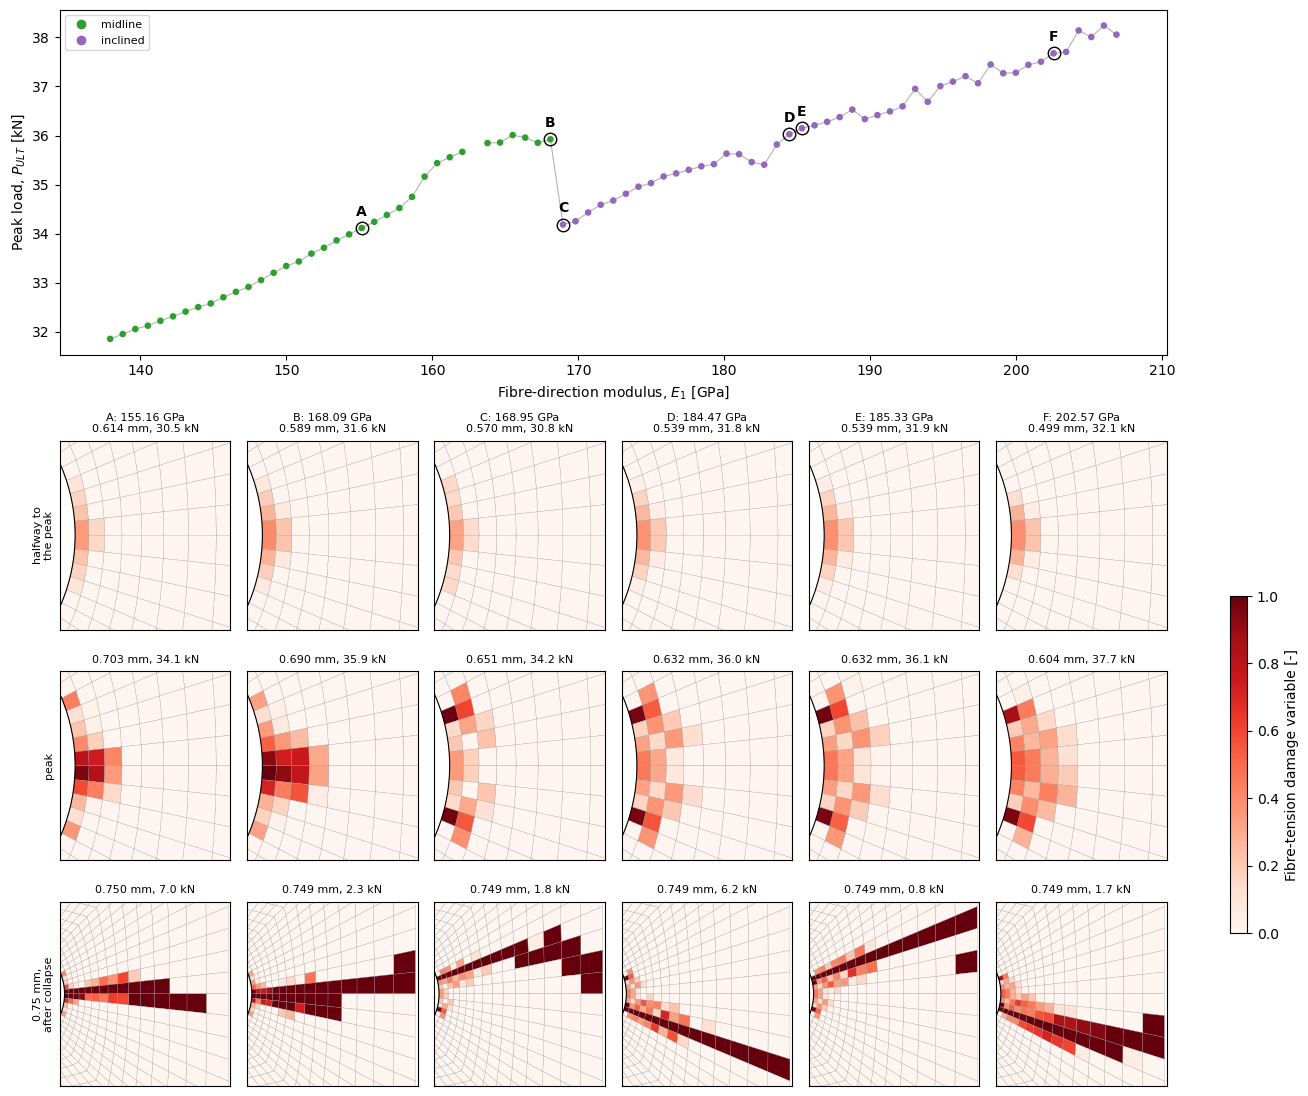

In [18]:
# Element centroids of mesh M1 (the same in every run), as radius from the hole's centre [mm] and angle from the net section [deg].
mesh_m1 = coarse[35][0]
nodes = np.array(mesh_m1["nodes"])  # node coordinates [mm]
centroid = {}  # element label -> (radius [mm], angle [deg])
for lab, el in zip(mesh_m1["labels"], mesh_m1["elements"]):
    # Centroid offsets from the hole's centre (38.1, 38.1) mm; the angle is folded into one quadrant (the mesh is symmetric).
    cx, cy = nodes[el].mean(axis=0)[:2] - 38.1
    centroid[lab] = (np.hypot(cx, cy), np.degrees(np.arctan2(abs(cy), abs(cx))))


def collapse_path(r):
    """'midline' or 'inclined' from the 0-deg elements that reach the fibre-tension criterion after the peak, 12 mm or more
    from the hole's centre (median angle from the net section below or above 6 deg); None if no such element."""
    # The peak frame, and the angles of the elements that start after it, beyond the three rings at the hole's edge.
    k = r["peak_index"]
    angles = [centroid[e][1] for e, f in r["ft0_init_order"] if f > k and centroid[e][0] > 12.0]
    if not angles:
        return None
    # 6 deg separates the midline row (about 3 deg) from the next radial row (about 8 deg).
    return "midline" if np.median(angles) < 6.0 else "inclined"


# Label every accepted run of the finest scan (None for a rejected one).
# The two collapse paths get their own colours, used for nothing else from here on; grey marks a run without a label.
COLOURS = {"midline": "tab:green", "inclined": "tab:purple", None: "0.5"}
scan[0.001]["path"] = [collapse_path(r) if a else None for r, a in zip(scan[0.001]["results"], scan[0.001]["ok"])]
# Part 3's points with the finest cap; B and C move to the two runs either side of this cap's drop (rows 35 and 36).
POINTS_FINE = {"A": 20, "B": 35, "C": 36, "D": 54, "E": 55, "F": 75}
fine = {i: full_run("a%02d_inc001" % i, x_a[i], 0.001) for i in POINTS_FINE.values()}
for name, i in POINTS_FINE.items():
    # Peak load [N] and displacement [mm] of the full run, against the scan run, and the full run's collapse path.
    res = fine[i][2]
    print("%s: E1 = %.2f GPa; full run P_ULT %.1f N at %.4f mm; scan run %.1f N at %.4f mm; %s"
          % (name, E1_GPA[i], res["f_peak_n"], res["u2_peak_mm"], scan[0.001]["P"][i], scan[0.001]["d"][i], collapse_path(res)))
# How many runs take each path, and the E1 range [GPa] and peak displacements [mm] of each.
paths = scan[0.001]["path"]
print("maxinc 0.001: midline %d, inclined %d, unlabelled %d" % (paths.count("midline"), paths.count("inclined"),
                                                                sum(p is None for p in paths)))
for path in ("midline", "inclined"):
    sel = np.array([p == path for p in paths])
    print("maxinc 0.001, %-8s E1 %.2f-%.2f GPa, delta_ULT %.3f-%.3f mm"
          % (path, E1_GPA[sel].min(), E1_GPA[sel].max(), np.nanmin(scan[0.001]["d"][sel]), np.nanmax(scan[0.001]["d"][sel])))
# The same figure as in Part 3, now with the finest cap; the dots are coloured by the path of each scan run.
damage_figure(POINTS_FINE, fine, E1_GPA, scan[0.001]["P"], FRAME_U2, colors=[COLOURS[p] for p in paths],
              legend={p: COLOURS[p] for p in ("midline", "inclined")})

With the finest cap the damage separates the runs cleanly, and the label splits the line in two at the one drop. Every run up
to 168.09 GPa is **midline** (35 runs, $\delta_{ULT}$ 0.690&ndash;0.733 mm); every run from 168.95 GPa on is **inclined** (45
runs, 0.597&ndash;0.651 mm). The maps show why. At the peak, the late runs (A, B) have the net-section block at 0.8&ndash;1
and the off-axis elements light, and after the collapse their band runs straight out along the midline. The early runs
(C to F) have their off-axis elements near 1 at the peak, with a lighter block (0.35&ndash;0.55), and break along an inclined band
that leaves the hole at about 13&ndash;19°, upwards in C and E, downwards in D and F. So late collapse goes with a horizontal
crack and early collapse with an inclined one; NB9's cap hid the link. Along the inclined branch which mesh row
breaks (the median angles fall near 8°, 13° and 17°) hardly matters for $P_{ULT}$: whether the crack is inclined at all does.

Against Part 3, input by input. The jump does not fall between the same two runs: with NB9's cap it lies between 167.23 and
168.09 GPa, with the finest between 168.09 and 168.95 GPa. A: an inclined band at 0.739 mm and 35.4 kN with NB9's cap, a
midline band at 0.703 mm and 34.1 kN with the finest, so the cap changed the path and put the peak 1.2 kN too high. 168.09 GPa
(Part 3's C, here B): 33.6 kN on an inclined band with NB9's cap, 35.9 kN on the midline with the finest, 2.3 kN too low. D:
38.3 kN at 0.688 mm with NB9's cap, 36.0 kN at 0.632 mm with the finest, an inclined band both times: the coarse run was late
as well as 2.3 kN too high. E and F take the same path with both caps and differ by 0.3 and 0.1 kN. So a coarse cap does not
always change the path, but where it does it moves the peak by up to 2.3 kN and breaks the link between timing and crack.

One more feature of the midline branch: $P_{ULT}$ climbs 0.7 kN between 158.6 and 160.3 GPa, about twice its usual rate, and
$\delta_{ULT}$ rises from 0.702 to 0.712 mm. The 0.002 line has it too, so it is not the solver, and the path does not change
there. It is a kink, not a jump, and this notebook leaves it there.

### Step 2 &ndash; The two runs either side of the drop

With the finest cap the path switches between $E_1=168.09$ and 168.95 GPa (points B and C of Step 1, rows 35 and 36). The cell draws
their load&ndash;displacement curves.

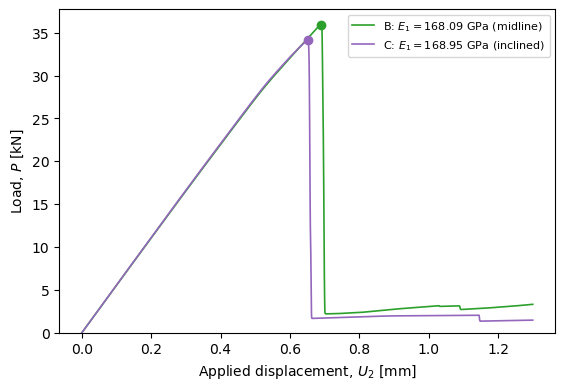

In [19]:
# Points B and C, either side of the drop, with the finest cap (already loaded in Step 1).
I_LEFT, I_RIGHT = POINTS_FINE["B"], POINTS_FINE["C"]
pair = {I_LEFT: fine[I_LEFT], I_RIGHT: fine[I_RIGHT]}
# The two curves and their peaks [kN against mm], labelled by point, E1 and the path of the scan run.
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for name, i in (("B", I_LEFT), ("C", I_RIGHT)):
    # Load [kN] against applied displacement [mm] in the colour of the run's path, and the peak as a dot.
    res, color = pair[i][2], COLOURS[scan[0.001]["path"][i]]
    ax.plot(res["u2"], np.array(res["rf2"]) / 1e3, color=color, lw=1.2,
            label="%s: $E_1=%.2f$ GPa (%s)" % (name, E1_GPA[i], scan[0.001]["path"][i]))
    ax.plot(res["u2_peak_mm"], res["f_peak_n"] / 1e3, "o", color=color)
# Axes from zero load, a legend, and the figure.
ax.set(xlabel="Applied displacement, $U_2$ [mm]", ylabel="Load, $P$ [kN]", ylim=(0, None))
ax.legend(fontsize=8)
plt.show()

The two curves lie on top of each other up to about 0.6 mm. The right run (C, 168.95 GPa, inclined) peaks at 0.651 mm and
34.2 kN; the left run (B, 168.09 GPa, midline) carries on to 0.690 mm and 35.9 kN; both then drop almost vertically to about
2 kN. A stiffer plate, which should be slightly stronger, breaks 1.7 kN earlier.

Where do the two runs part? The full runs tabulate the damage of every element, ply and mode at the displacements of
`FRAME_U2`, every 0.005 mm from 0.540 to 0.620 mm. The cell compares the two runs at each of them, over all plies and all
four modes, and prints the largest differences in the upper right quarter of the plate, where the inclined band of the
right run starts.

In [20]:
PLY_ANGLE = {1: 45, 2: 0, 3: -45, 4: 90, 5: 90, 6: -45, 7: 0, 8: 45}  # NB6's [45/0/-45/90]s, top ply first [deg]
MODES = ("damage_ft", "damage_fc", "damage_mt", "damage_mc")


def damage_by_key(rows):
    """{(element, ply, mode): damage} for the damaged rows of one tabulated frame (absent = 0), in the quarter x, y > 38.1 mm."""
    return {(int(row["element_label"]), int(row["ply"]), m): float(row[m]) for row in rows for m in MODES
            if float(row[m]) > 0.0 and float(row["x"]) > 38.1 and float(row["y"]) > 38.1}


# At each tabulated displacement up to 0.62 mm, the three largest differences (right run minus left run).
for u in FRAME_U2[:18]:
    tag = "u%.4f" % u
    left, right = (damage_by_key(pair[i][1][tag]) for i in (I_LEFT, I_RIGHT))
    keys = sorted(set(left) | set(right), key=lambda k: -abs(right.get(k, 0.0) - left.get(k, 0.0)))
    # Element (radius, angle), ply (angle), mode: damage in the left and right run. Plies 1 and 8 (and 2 and 7) behave alike.
    print("%.3f mm: " % u + "; ".join("el. %d (%.1f mm, %.0f deg) ply %d (%+d deg) %s: %.2f / %.2f"
                                      % (k[0], *centroid[k[0]], k[1], PLY_ANGLE[k[1]], k[2][7:], left.get(k, 0.0), right.get(k, 0.0))
                                      for k in [k for k in keys if k[1] <= 4][:2]))

0.500 mm: el. 750 (9.9 mm, 2 deg) ply 2 (+0 deg) ft: 0.06 / 0.08; el. 720 (9.9 mm, 11 deg) ply 1 (+45 deg) mt: 0.93 / 0.92
0.540 mm: el. 705 (9.9 mm, 16 deg) ply 1 (+45 deg) mt: 0.13 / 0.00; el. 705 (9.9 mm, 16 deg) ply 1 (+45 deg) ft: 0.00 / 0.02
0.545 mm: el. 705 (9.9 mm, 16 deg) ply 1 (+45 deg) mt: 0.17 / 0.00; el. 705 (9.9 mm, 16 deg) ply 1 (+45 deg) ft: 0.00 / 0.03
0.550 mm: el. 705 (9.9 mm, 16 deg) ply 1 (+45 deg) mt: 0.21 / 0.00; el. 705 (9.9 mm, 16 deg) ply 1 (+45 deg) ft: 0.00 / 0.04
0.555 mm: el. 705 (9.9 mm, 16 deg) ply 1 (+45 deg) mt: 0.24 / 0.00; el. 705 (9.9 mm, 16 deg) ply 1 (+45 deg) ft: 0.00 / 0.04
0.560 mm: el. 705 (9.9 mm, 16 deg) ply 1 (+45 deg) mt: 0.26 / 0.00; el. 705 (9.9 mm, 16 deg) ply 1 (+45 deg) ft: 0.00 / 0.08
0.565 mm: el. 705 (9.9 mm, 16 deg) ply 1 (+45 deg) mt: 0.29 / 0.00; el. 705 (9.9 mm, 16 deg) ply 1 (+45 deg) ft: 0.00 / 0.12
0.570 mm: el. 705 (9.9 mm, 16 deg) ply 1 (+45 deg) mt: 0.37 / 0.00; el. 705 (9.9 mm, 16 deg) ply 1 (+45 deg) ft: 0.00 / 0.16
0.

At 0.50 mm the largest differences are 0.02 or less, the size you would expect from a 0.5% change of $E_1$. From 0.540 mm
one element stands out, and it stays at the top of the list: **element 705**, on the hole's edge 16° from the net section,
in its **+45° ply** (ply 1; ply 8 behaves the same). In the left run that ply has started to fail in **matrix tension**
(0.13 at 0.540 mm, 0.47 at 0.575 mm) and has no fibre damage. In the right run it has started to fail in **fibre tension**
(0.02 at 0.540 mm, 0.71 at 0.620 mm) and has no matrix damage. From 0.580 mm the difference spreads to the 0° ply of the same
element: its fibre damage is 0.04 in the left run and 0.32 in the right one, 0.13 against 0.74 by 0.615 mm.

So the runs part in one ply of one element, by a different mode starting first, and only afterwards does the 0° ply, the
one that breaks the plate, follow. The filmstrips show the same story in space: the fibre-tension damage of the 0° plies,
then that of the +45° plies, for the two runs at six displacements, with element 705 outlined in blue in the +45° maps. The next cell defines
`filmstrip`, which draws a row of damage maps for each run, one column per displacement.

fibre-tension damage, 0-deg plies


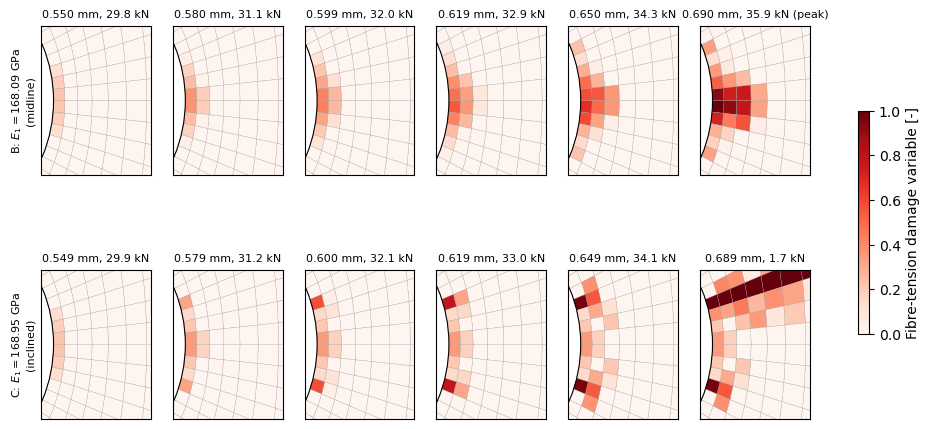

fibre-tension damage, +45-deg plies


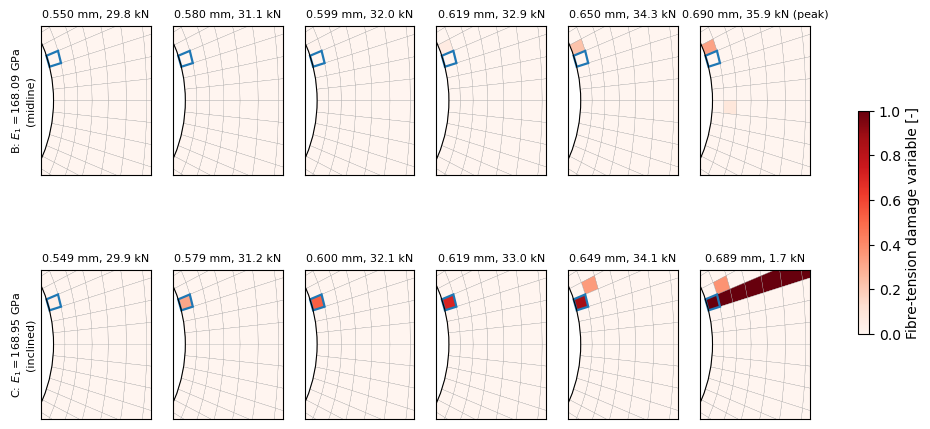

In [21]:
def filmstrip(entries, u_list, column="damage_ft", plies=(2, 7), xlim=(46.8, 54.0), ylim=(33.2, 43.0), highlight=()):
    """Draw the damage `column` of `plies` at the displacements u_list [mm]: one row per entry, one column per displacement.
    The elements in `highlight` (labels) are outlined in blue.

    entries : list of (label, (mesh, rows by frame tag, result)) -- the label names the row.
    """
    # One panel per entry and displacement.
    fig, axes = plt.subplots(len(entries), len(u_list), figsize=(1.9 * len(u_list) + 1.0, 2.9 * len(entries)), squeeze=False)
    for row, (label, (mesh, rows_by_tag, res)) in enumerate(entries):
        for col, u in enumerate(u_list):
            # The frame drawn (the last one at or below u), its displacement and load, and whether it is the peak frame.
            tag = "u%.4f" % u
            k = res["tagged_frames"][tag]
            # Draw the panel, then its title: the frame's applied displacement and load.
            pc = damage_map(axes[row, col], mesh, rows_by_tag[tag], column, plies, xlim, ylim, highlight)
            axes[row, col].set_title("%.3f mm, %.1f kN%s" % (res["u2"][k], res["rf2"][k] / 1e3,
                                     " (peak)" if k == res["peak_index"] else ""), fontsize=8)
        # The run's label at the left of its row.
        axes[row, 0].set_ylabel(label, fontsize=8)
    # One colour bar for the whole figure.
    fig.colorbar(pc, ax=axes, shrink=0.5, label={"damage_ft": "Fibre-tension", "damage_fc": "Fibre-compression", "damage_mt": "Matrix-tension",
                                                 "damage_mc": "Matrix-compression"}[column] + " damage variable [-]")
    plt.show()


# Element 705: the hole's edge at 16 deg above the net section, whose +45-deg plies part the two runs.
EL_TIE = 705
# The two runs: fibre tension of the 0-deg plies (first figure), then of the +45-deg plies (second, element 705 outlined).
# Plies 2 and 7 are the 0-deg plies, 1 and 8 the +45-deg plies (top ply first).
rows_pair = [("%s: $E_1=%.2f$ GPa\n(%s)" % (n, E1_GPA[i], scan[0.001]["path"][i]), pair[i]) for n, i in (("B", I_LEFT), ("C", I_RIGHT))]
for plies, name in (((2, 7), "0-deg plies"), ((1, 8), "+45-deg plies")):
    print("fibre-tension damage, " + name)
    filmstrip(rows_pair, [0.55, 0.58, 0.60, 0.62, 0.65, 0.69], plies=plies, highlight=(EL_TIE,) if plies == (1, 8) else ())

In the 0° plies (first figure) the two runs look alike at 0.55 mm. From 0.58 mm the right run (C, 168.95 GPa) builds damage
in element 705, the hole-edge element 16° above the net section (outlined in the second figure), and in its mirror image
below the hole, while the net-section block stays light: element 705's 0° ply is at 0.74 by 0.615 mm, against 0.13 in the
left run. The left run (B) does the opposite, and its net-section block reaches about 0.9 at the peak. The right run then
breaks along a band that leaves element 705 at an angle; the left run breaks straight along the net section.

In the +45° plies (second figure) the left run has almost no fibre damage until its peak. In the right run the +45° fibres of
element 705 (outlined) are damaged from 0.58 mm on (about 0.3, then 0.5&ndash;0.7), before its 0° ply follows; at the end the band
breaks the +45° fibres along the same inclined row, starting at element 705, outlined in blue.

### Step 3 &ndash; What tips the race: a tie between two Hashin criteria

Why does the +45° ply of element 705 start in matrix tension in one run and in fibre tension in the other? NB1 introduced the
two criteria; in plane stress, with the shear weight $\alpha=1$ used throughout the series (NB1), they read

$$F_{ft}=\left(\frac{\hat\sigma_{11}}{X_T}\right)^2+\left(\frac{\hat\tau_{12}}{S_L}\right)^2,\qquad
F_{mt}=\left(\frac{\hat\sigma_{22}}{Y_T}\right)^2+\left(\frac{\hat\tau_{12}}{S_L}\right)^2,$$

where
- $\hat\sigma_{11},\hat\sigma_{22},\hat\tau_{12}$ are the effective stresses along the fibres, across them and in shear, in the ply's own axes [MPa],
- $X_T$, $Y_T$, $S_L$ are the tensile strengths along and across the fibres and the shear strength [MPa],

and a mode starts when its $F$ reaches 1 ([Lapczyk & Hurtado, 2007, p. 2335](https://doi.org/10.1016/j.compositesa.2007.01.017)).
Both contain the same shear term. In a ±45° ply near the hole, shear is a large part of the stress, so the two criteria
rise together.

The full runs do not tabulate the criteria at every frame, but their output databases have them. The extraction script of
NB9 reads them for a few elements with the option `history_elements=` (Abaqus's own Python, no licence token), and the cell
draws $F_{ft}$ and $F_{mt}$ of element 705's +45° ply for the two runs either side of the drop. For the left run with NB9's cap it prints the two frames around the moment the criteria
reach 1.

E_1=168.09 GPa, maxinc 0.001       fibre tension   never reaches 1 (at most 0.993)
E_1=168.09 GPa, maxinc 0.001       matrix tension  reaches 1 at U2 = 0.5238 mm


E_1=168.95 GPa, maxinc 0.001       fibre tension   reaches 1 at U2 = 0.5256 mm
E_1=168.95 GPa, maxinc 0.001       matrix tension  reaches 1 at U2 = 0.5745 mm


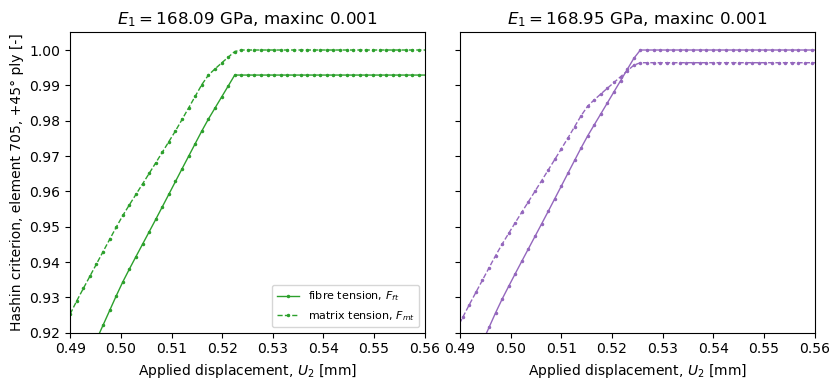

maxinc 0.01, E1 = 168.09 GPa: U2 = 0.5223 mm, F_ft 0.9928, F_mt 0.9997; next frame U2 = 0.5353 mm, F_ft 1.0000, F_mt 1.0000


In [22]:
# NB9's extraction script (Abaqus-side, run only through `abaqus python`).
EXTRACT = Path("../scripts/extract_open_hole_tension.py")


def criteria_history(name):
    """Run-or-load the per-frame Hashin criteria and damage of a few elements of a finished full run (abaqus python reads
    the run's .odb and takes no licence token). Returns the rows of element EL_TIE, ply 1 (+45 deg), in frame order."""
    # The history file next to the run's .odb, and the command that writes it for element 705 and its neighbours.
    path = RUNS / "full" / (name + "_history.csv")
    command = ["abaqus", "python", str(EXTRACT.resolve()), "job=" + name, "history_elements=705,750,749,748,735,720,719,704",
               "history_csv=" + path.name]
    # Run it if allowed (it needs the run's .odb in its folder), else print the command.
    if not path.exists() and RUN_CAMPAIGN:
        subprocess.run(command, cwd=str(path.parent), shell=(sys.platform == "win32"), check=True)
    elif not path.exists():
        print("missing %s; run from %s:\n    %s" % (path.name, path.parent, " ".join(command)))
    # Keep only element EL_TIE, ply 1; the rows are already in frame order.
    with open(path, newline="") as f:
        return [row for row in csv.DictReader(f) if int(row["element_label"]) == EL_TIE and int(row["ply"]) == 1]


# The two runs either side of the drop (finest cap): F_ft and F_mt of element 705's +45-deg ply.
runs_tie = [("a35_inc001", "$E_1=168.09$ GPa, maxinc 0.001", COLOURS["midline"]), ("a36_inc001", "$E_1=168.95$ GPa, maxinc 0.001", COLOURS["inclined"])]
fig, axes = plt.subplots(1, 2, figsize=(8.5, 4.0), sharey=True)
for ax, (name, label, color) in zip(axes, runs_tie):
    # The ply's history, and the applied displacement of each frame [mm].
    h_rows = criteria_history(name)
    u = np.array([float(r["u2"]) for r in h_rows])
    # F_ft solid, F_mt dashed; one dot per frame shows the increments.
    for col, ls, crit in (("HSNFTCRT", "-", "fibre tension, $F_{ft}$"), ("HSNMTCRT", "--", "matrix tension, $F_{mt}$")):
        ax.plot(u, [float(r[col]) for r in h_rows], ls, color=color, marker=".", ms=3, lw=1, label=crit)
        # The first frame at which this criterion reaches 1 (None if never).
        hit = next((u[k] for k, r in enumerate(h_rows) if float(r[col]) >= 1.0), None)
        # Below 1 at every frame: the highest value it reaches instead.
        top = max(float(r[col]) for r in h_rows)
        print("%-34s %-15s " % (label.replace("$", ""), crit.split(",")[0])
              + ("reaches 1 at U2 = %.4f mm" % hit if hit else "never reaches 1 (at most %.3f)" % top))
    # A close view of the last 0.07 mm before the criteria reach 1.
    ax.set(xlim=(0.49, 0.56), ylim=(0.92, 1.005), title=label, xlabel="Applied displacement, $U_2$ [mm]")
# One y label and one legend for the two panels.
axes[0].set_ylabel("Hashin criterion, element 705, +45° ply [-]")
axes[0].legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()
# The same left inputs with NB9's cap: the last frame before both criteria reach 1, and the first frame at or above it.
h_rows = criteria_history("a35_inc010")
u = np.array([float(r["u2"]) for r in h_rows])
f_ft, f_mt = (np.array([float(r[c]) for r in h_rows]) for c in ("HSNFTCRT", "HSNMTCRT"))
k = int(np.argmax(np.maximum(f_ft, f_mt) >= 1.0))
print("maxinc 0.01, E1 = 168.09 GPa: U2 = %.4f mm, F_ft %.4f, F_mt %.4f; next frame U2 = %.4f mm, F_ft %.4f, F_mt %.4f"
      % (u[k - 1], f_ft[k - 1], f_mt[k - 1], u[k], f_ft[k], f_mt[k]))

In both runs the two criteria climb side by side, $F_{mt}$ (dashed) a little ahead, and the gap closes
as they approach 1: a near-tie. In the left run (168.09 GPa) $F_{mt}$ gets there first, at 0.5238 mm; matrix tension starts,
and $F_{ft}$ stops rising at 0.993: the +45° fibres never fail. In the right run (168.95 GPa) $F_{ft}$, slightly steeper,
overtakes just before the line and reaches 1 at 0.5256 mm; fibre tension starts and $F_{mt}$ stalls at 0.996 until 0.5745
mm, long after the fibres have begun to soften. A 0.5% stiffer fibre direction presumably loads the +45° fibres a little
more, and that is enough to swap the winner. That the losing criterion stops rising once the other mode has started is read
from the data; why it does is not checked here.

With NB9's cap (the last printed line) the same left inputs take increments of about 0.013 mm here. At 0.5223 mm $F_{ft}$ is
at 0.9928 and $F_{mt}$ at 0.9997, still just below 1; at the next increment, 0.5353 mm, both are at 1. The increment has
stepped over the tie: both modes start in the same increment, the fibres soften, and the plate goes down the inclined path,
as the right run does, 2.3 kN below the converged peak (C in Part 3, with its inclined band).

**The physical reading.** If the +45° ply at element 705 cracks in its matrix first, its fibres keep carrying their share of
the load, the 0° ply next to them is not overloaded, and the 0° damage keeps concentrating where the stress concentration is
highest, on the net section: the crack runs straight across the plate, late. If its fibres break first, the load they
carried moves to the 0° ply of the same element, whose fibre damage then outruns that of the net-section block (0.99 against
0.35 at the peak of run C, Step 1), and the crack leaves the hole from there, early. A tie between two Hashin modes in one ply of one
element at the hole's edge decides which of two 0° failure paths the whole plate takes, and the peak load differs by 1.7 kN
(5%) between them.

> **Note:** the inclined crack runs along a radial row of the mesh. Unless the crack path is known in advance, meshes other
> than uniform square ones favour some band directions over others
> ([Bažant & Oh, 1983, p. 163](https://doi.org/10.1007/BF02486267)), so on mesh M1 the candidate inclined paths are the mesh
> rows. That a near-tie at the hole's edge can switch the path is a property of the model; the angle and the size of the
> switch may depend on the mesh. A repeat on a finer mesh (M2) would tell.

## Summary

- A polynomial chaos expansion converges for any output with a finite variance, but slowly on one with jumps; at an
  affordable order the jumps leave an error floor. Differences of an output along a line of closely spaced runs measure the
  roughness: they fall with the spacing for a smooth output and stay flat for a rough one.
- The 11% of the variance of $P_{ULT}$ that NB10's surrogate leaves unexplained is such a rough layer: the residuals of
  neighbouring runs are unrelated, and 93% of it is the timing of the collapse.
- Along $E_1$, most of the rough layer is the solver's increment cap. Once softening starts, equilibrium is no longer
  unique, and with NB9's `maxinc` = 0.01 runs 0.5% apart reach the peak with their damage in different places, break along
  different mesh rows, and a late collapse is not a straight one. The peak jumps every few runs (difference level 629 N,
  16 changes above 1 kN) and sits 0.7 kN too high on average where both caps collapse late (up to 1.2 kN), and up to 2.3 kN off where the cap
  changes the path; with 0.001 a single jump is left (146 N, one change of 1.7 kN). A cap
  converged at the nominal point was not converged over the input distribution.
- The jump that is left is the model's: the plate switches between two collapse paths, each a smooth branch. With the finest
  cap the damage tells them apart. Late runs (0.69&ndash;0.73 mm) have the net-section block winning and a crack straight
  along the midline; early runs (0.60&ndash;0.65 mm) have the hole-edge elements 16° from the net section winning and a crack
  along an inclined mesh row. A near-tie between the fibre- and matrix-tension criteria in the +45° ply of one element at the
  hole's edge decides which; a coarse increment steps over the tie.

**What's next.** [NB12](12_mixture_of_experts.ipynb) takes up the picture this notebook ended with: two smooth branches,
one for each way the plate breaks, and a jump between them that is smaller than the spread of the peak load, so that one
polynomial rounds it off. NB12 learns, on two toy problems whose answer is known and with no Abaqus run, a surrogate made of
one smooth **expert** per branch and a **gate** that learns from the runs which expert applies. In other words, NB12 introduces the idea of using **a mixture of experts** to train a surrogate.